#### Notice, in this notebook, the naming for variable might not seem to be consistent, because i haven't made a methodological,efficient way to name variables in machine learning

In [3]:
import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import cv2
import os
from PIL import Image

C:\Users\thaim\anaconda3\envs\tf210\lib\site-packages\requests\__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


In [4]:
# This function "load_paths" serve to find images's names from a dataframe in a physical folder and joing these paths to dataframe at same images's names
def load_paths(df,folder):
    paths = []
    for root,_,files in os.walk(f"{os.getcwd()}{folder}"):
        for fname in files :
            if fname.lower().endswith(('.png','jpg','jpeg','bmp','gif')):
                full_path = os.path.join(root,fname)
                bname = os.path.splitext(fname)[0]
                paths.append(
                    {
                        "path" : full_path,
                        df.columns[0] : bname
                    }
                )
    return pd.DataFrame(paths).merge(df,on=df.columns[0])

def get_paths(folder):
    paths=[]
    for root,_,files in os.walk(f"{os.getcwd()}{folder}"):
        for fname in files:   
            full_path = os.path.join(root,fname)
            paths.append(full_path)
    return paths

In [5]:
# This function "load_img" take paths and find the files from paths to import images in form of numpy array
def load_img(path,size=None):
    img = Image.open(path).convert("RGB")
    if size : 
        img = img.resize(size)
    return np.array(img)

In [6]:
# This function "save_by_label" take X (images), Y (labels), make a folder with given name "out_dir" and save grouped images by label name in each folder
def save_by_label(X, Y, out_dir='dataset_by_label', prefix='img'):
    """
    X: np.ndarray, shape (N,H,W) or (N,H,W,3), dtype uint8 [0–255] or float [0–1]
    Y: array-like of length N, labels (str or int)
    out_dir: root folder to create class subfolders in
    prefix: filename prefix, images will be named prefix_i.png
    """
    os.makedirs(out_dir, exist_ok=True)
    N = len(Y)
    
    for i, (img, label) in enumerate(zip(X, Y)):
        # 1) Prepare the label folder
        label_str = str(label)
        label_dir = os.path.join(out_dir, label_str)#create url string for label folder
        os.makedirs(label_dir, exist_ok=True)#Make dir/folder, if exist then no needed

        # 2) Convert image to uint8 BGR if needed
        #    handle float [0,1] → uint8 [0,255]
        if img.dtype in (np.float32, np.float64):
            img_uint8 = (img * 255).round().astype(np.uint8) # convert to unint8 cuz float pixels produce weird color
        else:
            img_uint8 = img

        #    if it’s RGB, convert to BGR for cv2
        if img_uint8.ndim == 3 and img_uint8.shape[2] == 3: # verify 3 dims (width,height,color-channels == 3)
            to_save = cv2.cvtColor(img_uint8, cv2.COLOR_RGB2BGR)#reset color channel from opencv Default BGR
        else:
            # grayscale or single‐channel
            to_save = img_uint8

        # 3) Choose a filename
        fname = f"{prefix}_{i:05d}.png"#name the img
        save_path = os.path.join(label_dir, fname)#path for the img

        # 4) Write it out
        cv2.imwrite(save_path, to_save)#save it accord to it's label (by index order of X,Y)

    print(f"Saved {N} images into {out_dir!r} with {len(set(Y))} class folders.")

In [7]:
#some plotting preprocessing image transformation function to see the changes
def plot_transformation(original_img,transformed_img,size=(10,5),id_img=None):
    fig,axes = plt.subplots(1,2,figsize=size)
    fig.patch.set_facecolor("black")
    axes[0].imshow(original_img)
    axes[0].set_title("Raw",color="white")
    axes[0].axis("off")
    axes[1].imshow(transformed_img,cmap="gray" if transformed_img.ndim==2 else None)
    axes[1].set_title("Preprocessed",color="white")
    axes[1].axis("off")
    if id_img :
        fname = os.path.join("preprocessed_previews",f"sample_{id_img:03d}.png")
    else :
        fname = os.path.join("preprocessed_previews",f"sample.png")
    fig.savefig(fname,dpi=300,bbox_inches='tight')

In [59]:
#display sample for preprocessed images
def show_df_imgs(df_ds,
                 grayscale: bool = False,
                 fname: str = "sample_imgs.png",
                 title: str = "sample_imgs",
                 save: bool = False,
                 label=True):
    # choose colormap
    cmap = "gray" if grayscale else None

    # 1) set up the 5×5 grid with black background
    fig, axes = plt.subplots(5, 5, figsize=(10, 10), facecolor="black")
    axes = axes.flatten()
    
    # 2) human-readable labels
    labels = [
        "0 - No_DR",
        "1 - Mild",
        "2 - Moderate",
        "3 - Severe",
        "4 - Proliferate_DR",
    ]
    
    # 3) plot each image
    for idx, ax in enumerate(axes):
        ax.axis("off")
        img = df_ds["image"].iloc[idx]
        lbl = labels[int(df_ds["label"].iloc[idx])]
        
        ax.imshow(img, cmap=cmap)
        if label: 
            ax.set_title(lbl, color="white", fontsize=10, pad=2)

    # 4) super-title
    fig.suptitle(title, color="white", fontsize=18, y=1.02)
    plt.tight_layout()

    # 5) optionally save
    if save:
        # ensure the figure background stays black
        fig.savefig(
            fname,
            dpi=300,
            facecolor=fig.get_facecolor(),
            edgecolor="black",
            bbox_inches="tight"
        )
        plt.show()   # close to prevent display duplication
    else:
        plt.show()


In [9]:
#save the preprocessed use the previous function "save_by_label"
def save_preprocessed(folder_name="untitled",df_ds=None):
    imgs = np.stack(df_ds["image"].values,axis=0)
    labels = df_ds["label"].values
    save_by_label(X=imgs,Y=labels,out_dir=folder_name)

In [10]:
#convert dataset to dataframe by extracting manually images and labels and put them all in dataframe, sometime gpu can't handle if it's a very big dataset
def convert_df (ds):
    imgs = []
    labels = []
    for b_imgs,b_labels in ds:
        imgs.append(b_imgs.numpy())
        labels.append(b_labels.numpy())
    df_ds = pd.DataFrame({
        "image": imgs,
        "label": labels
    }
    )
    return df_ds


In [11]:
#get dataset from directory with seed key = 42 ( same random draw as everytime other times with seed = 42 ), batchsize none because it's probably not needed
ds = tf.keras.utils.image_dataset_from_directory(
    "dataset/dataset_splits/balanced_ds",
    seed=42,
    batch_size=None,
    image_size=(224,224),
    label_mode="categorical"
)

Found 3540 files belonging to 5 classes.


In [12]:
#for validation dataset
ds_val = tf.keras.utils.image_dataset_from_directory(
    "dataset/dataset_splits/sample_ds",
    seed = 42,
    batch_size = None,
    image_size = (224,224),
    label_mode="categorical"
)

Found 1770 files belonging to 5 classes.


In [13]:
#convert them to df for easier manipulation (personally i find it is)
df_ds = convert_df(ds)
df_ds_val = convert_df(ds_val)

In [13]:
df_ds.head()

,image,label
0,"[[[0.0, 0.0, 0.0], [1.0, 1.0, 1.0], [0.0, 0.0,...","[1.0, 0.0, 0.0, 0.0, 0.0]"
1,"[[[0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0,...","[0.0, 0.0, 0.0, 0.0, 1.0]"
2,"[[[0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0,...","[0.0, 0.0, 0.0, 1.0, 0.0]"
3,"[[[0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0,...","[1.0, 0.0, 0.0, 0.0, 0.0]"
4,"[[[0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0,...","[0.0, 0.0, 0.0, 0.0, 1.0]"


In [14]:
df_ds_val.head()

,image,label
0,"[[[0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0,...","[0.0, 1.0, 0.0, 0.0, 0.0]"
1,"[[[0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0,...","[0.0, 0.0, 1.0, 0.0, 0.0]"
2,"[[[0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0,...","[0.0, 1.0, 0.0, 0.0, 0.0]"
3,"[[[0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0,...","[0.0, 1.0, 0.0, 0.0, 0.0]"
4,"[[[0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0,...","[0.0, 1.0, 0.0, 0.0, 0.0]"


In [14]:
#convert values ["image"] and ["label"]
# image type float32 to uint8
df_ds["image"] = df_ds["image"].apply(lambda i:i.astype("uint8"))
df_ds_val["image"] = df_ds_val["image"].apply(lambda i : i.astype("uint8"))
# label is one hot encoded, let's extract the true value by taking dot product to [0,1,2,3,4]
df_ds["label"] = df_ds["label"].apply(lambda l: np.dot(l.astype("uint8"),[0,1,2,3,4]))
df_ds_val["label"] = df_ds_val["label"].apply(lambda l: np.dot(l.astype("uint8"),[0,1,2,3,4]))
df_ds.head(),df_ds_val.head()
                                   

(                                               image  label
 0  [[[0, 0, 0], [1, 1, 1], [0, 0, 0], [0, 0, 0], ...      0
 1  [[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...      4
 2  [[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...      3
 3  [[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...      0
 4  [[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...      4,
                                                image  label
 0  [[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...      1
 1  [[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...      2
 2  [[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...      1
 3  [[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...      1
 4  [[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...      1)

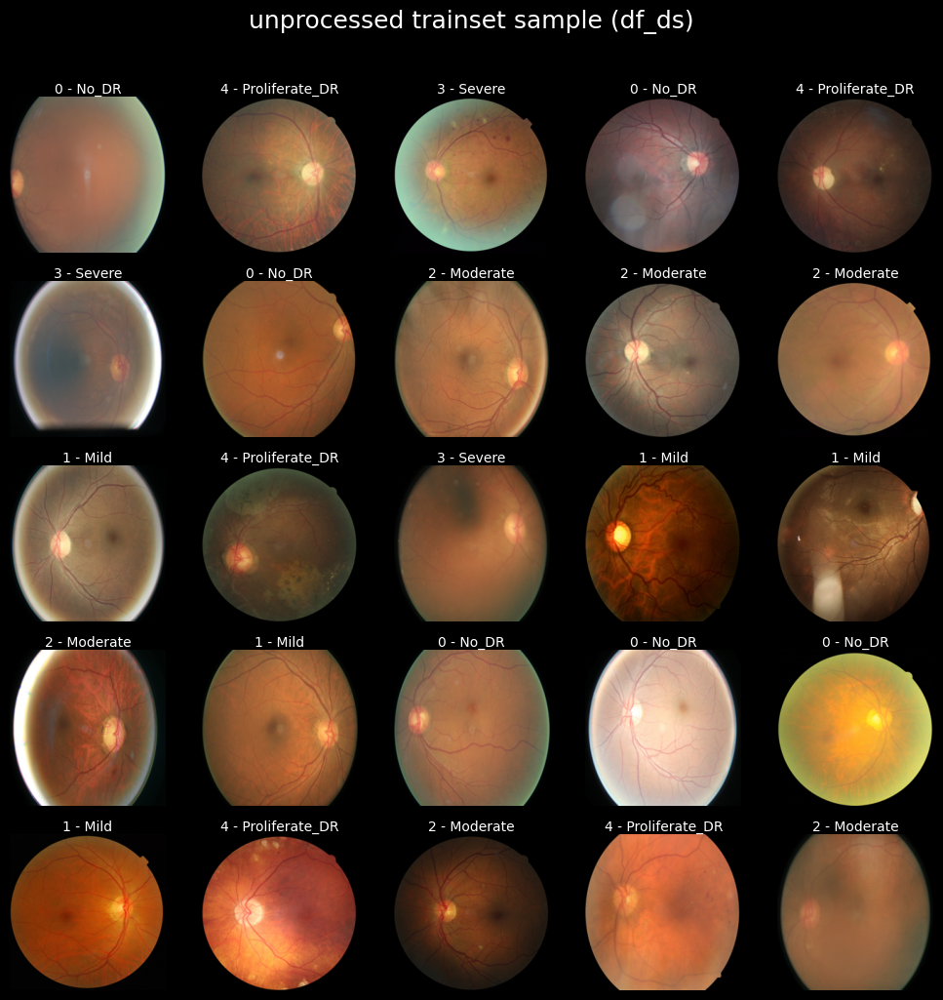

In [16]:
#display unprocessed images
show_df_imgs(df_ds.iloc[:50],title="unprocessed trainset sample (df_ds)",fname="unprocessed_trainset_sample.png",save = True)

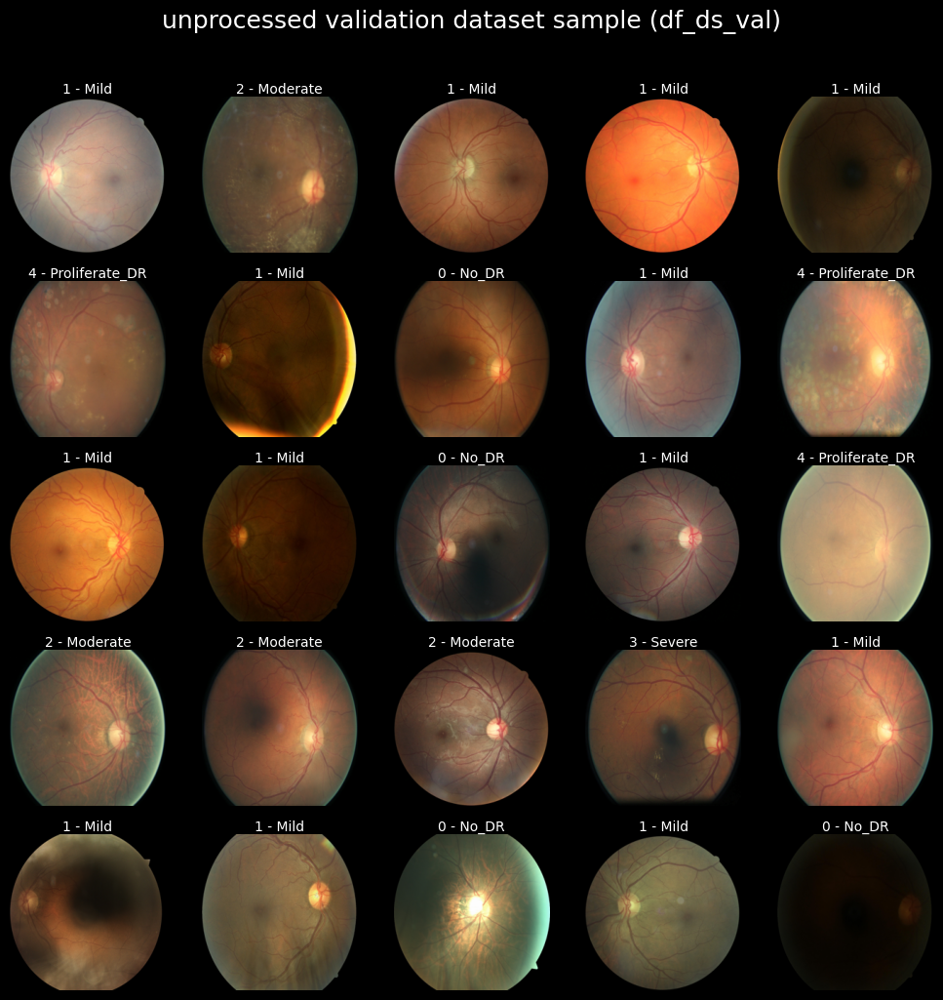

In [17]:
show_df_imgs(df_ds_val.iloc[:50],title="unprocessed validation dataset sample (df_ds_val)", fname="unprocessed_valset_sample.png",save=True)

In [18]:
#let's make a copy of df_ds to test preprocessing methods
df_ds_sample = df_ds.iloc[:50].copy(deep = True)
len(df_ds_sample),df_ds_sample["label"].value_counts()

(50,
 label
 4    13
 0    11
 1    10
 3     9
 2     7
 Name: count, dtype: int64)

In [42]:
#preprocessing_1 is simply to reduce noise by substracting gaussian blur but don't apply CLACHE which is to enhance constrast locally for model to better pickup the signal
def preprocessing_1(img, IMG_SIZE=224, sigmaX=None, gain=2)->np.ndarray:  # better at cropping
    """
    1) Read BGR → RGB, auto‐crop by gray mask.
    2) Resize to (IMG_SIZE,IMG_SIZE).
    3) Subtract a large‐sigma blur (unsharp‐mask) in color.
    """
    
    if sigmaX is None:
        sigmaX = 0.1 * IMG_SIZE

    # (find the circle that fit the retina in brief) x,y -> center of the circle on the gray img dimensions, and r is radius of the circle
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)  # convert the image to gray for getting contour
    _, thresh = cv2.threshold(gray, 10, 255, cv2.THRESH_BINARY)
    cntrs, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cnt = max(cntrs, key=cv2.contourArea)  # get the largest area contour
    (x, y), r = cv2.minEnclosingCircle(cnt)  # get the circle that fit the contour
    x, y, r = int(x), int(y), int(r)  # round them to integer

    # resize
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    # apply (gaussian blur substraction with weights)
    # weights are for the original img pixels and gaussian blur img pixel for substraction process // WeightA(gain) * orig_img - weightB(gain) * gaussian blur
    blur = cv2.GaussianBlur(img, (0, 0), sigmaX=sigmaX)
    img2 = cv2.addWeighted(img, gain, blur, -gain, 128)
    
    # mask outside circle //Notice, in my below sample images of preprocessing_1 doesn't have black masked because in my original function, i applied mask before noise substraction
    mask = np.zeros(img2.shape[:2], dtype=np.uint8)
    cv2.circle(mask, (x, y), r, 255, -1)  # draw the white circle to the mask
    img2 = cv2.bitwise_and(img2, img2, mask=mask)

    return np.clip(img2, 0, 255).astype(np.uint8)

In [43]:
#this preprocessing_2 apply CLACHE on the same preprocessed 1
def preprocessing_2(
    img: np.ndarray,
    IMG_SIZE: int = 224,
    sigmaX: float = None,
    clahe_clip: float = 2.0,
    clahe_grid: tuple = (8,8),
    gain = 2
) -> np.ndarray:
    
    if sigmaX is None:
        sigmaX = 0.1 * IMG_SIZE
        
     # (find the circle that fit the retina in brief) x,y -> center of the circle on the gray img dimensions, and r is radius of the circle
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)#convert the image to gray for getting contour
    _, thresh = cv2.threshold(gray, 10, 255, cv2.THRESH_BINARY)
    cntrs, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cnt = max(cntrs, key=cv2.contourArea)#get the largest area contour
    (x, y), r = cv2.minEnclosingCircle(cnt)#get the circle that fit the contour 
    x,y,r = int(x),int(y),int(r) #round them to integer

    mask = np.zeros_like(gray)
    cv2.circle(mask, (x,y), r, 255, -1) #draw the white circle to the mask 
    #apply bitwise_and operation to the image and mask (which mean where the bit is 255 it takes the pixel from "img" and when the bit is 0 it doesn't.
    img = cv2.bitwise_and(img, img, mask=mask) 

    #resize  
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    #apply (gaussian blur substraction with weights)  
    # weights are for the original img pixels and gaussian blur img pixel for substraction process // WeightA(gain) * orig_img - weightB(gain) * gaussian blur
    blur = cv2.GaussianBlur(img, (0,0), sigmaX=sigmaX)
    img2 = cv2.addWeighted(img, gain, blur, -gain, 128)
    
    # apply CLAHE on green channel of the preprocessed image (img2)
    lab = cv2.cvtColor(img2, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=clahe_clip, tileGridSize=clahe_grid)
    l2 = clahe.apply(l)
    lab2 = cv2.merge((l2, a, b))
    img2 = cv2.cvtColor(lab2, cv2.COLOR_LAB2RGB)
    
    return np.clip(img2, 0, 255).astype(np.uint8)

In [44]:
#This one is just with the black masked
def preprocessing_2_with_mask(
    img: np.ndarray,
    IMG_SIZE: int = 224,
    sigmaX: float = None,
    clahe_clip: float = 2.0,
    clahe_grid: tuple = (8,8),
    gain = 2
) -> np.ndarray:
    
    if sigmaX is None:
        sigmaX = 0.1 * IMG_SIZE
        
     # (find the circle that fit the retina in brief) x,y -> center of the circle on the gray img dimensions, and r is radius of the circle
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)#convert the image to gray for getting contour
    _, thresh = cv2.threshold(gray, 10, 255, cv2.THRESH_BINARY)
    cntrs, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cnt = max(cntrs, key=cv2.contourArea)#get the largest area contour
    (x, y), r = cv2.minEnclosingCircle(cnt)#get the circle that fit the contour 
    x,y,r = int(x),int(y),int(r) #round them to integer

    #resize 
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    #apply (gaussian blur substraction with weights) 
    # weights are for the original img pixels and gaussian blur img pixel for substraction process // WeightA(gain) * orig_img - weightB(gain) * gaussian blur
    blur = cv2.GaussianBlur(img, (0,0), sigmaX=sigmaX)
    img2 = cv2.addWeighted(img, gain, blur, -gain, 128)
    
    # apply CLAHE on green channel of the preprocessed image (img2)
    lab = cv2.cvtColor(img2, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=clahe_clip, tileGridSize=clahe_grid)
    l2 = clahe.apply(l)
    lab2 = cv2.merge((l2, a, b))
    img2 = cv2.cvtColor(lab2, cv2.COLOR_LAB2RGB)

    mask = np.zeros(img2.shape[:2], dtype=np.uint8)
    cv2.circle(mask, (x,y), r, 255, -1) #draw the white circle to the mask 
    #apply bitwise_and operation to the image and mask (which mean where the bit is 255 it takes the pixel from "img2" and when the bit is 0 it doesn't.
    img2 = cv2.bitwise_and(img2, img2, mask=mask) 
    
    return np.clip(img2, 0, 255).astype(np.uint8)



### Evaluate performance between 2 preprocessing methods both are set in same parameter follow :
- sigmaX = 10 (to substract noises)
- gain = 2
- img_size = 224x224
- grayscale = False

In [63]:
#cloning dataset for testing each preprocessing methods and directly feed to simple model to check result
prpc_v1s10g2_df = df_ds.copy(deep=True)
prpc_v2s10g2_df = df_ds.copy(deep=True)
prpc_v1s10g2_df["image"] = prpc_v2s10g2_df["image"].apply(lambda x : preprocessing_1(x,sigmaX=10,gain=2))
prpc_v2s10g2_df["image"] = prpc_v1s10g2_df["image"].apply(lambda x : preprocessing_2(x,sigmaX=10,gain=2))

In [64]:
#preparing validation data 
prpc_v1s10g2_val = df_ds_val.copy(deep=True)
prpc_v2s10g2_val = df_ds_val.copy(deep=True)
prpc_v1s10g2_val["image"] = prpc_v1s10g2_val["image"].apply(lambda x : preprocessing_1(x,sigmaX=10,gain=2))
prpc_v2s10g2_val["image"] = prpc_v2s10g2_val["image"].apply(lambda x : preprocessing_2(x,sigmaX=10,gain=2))

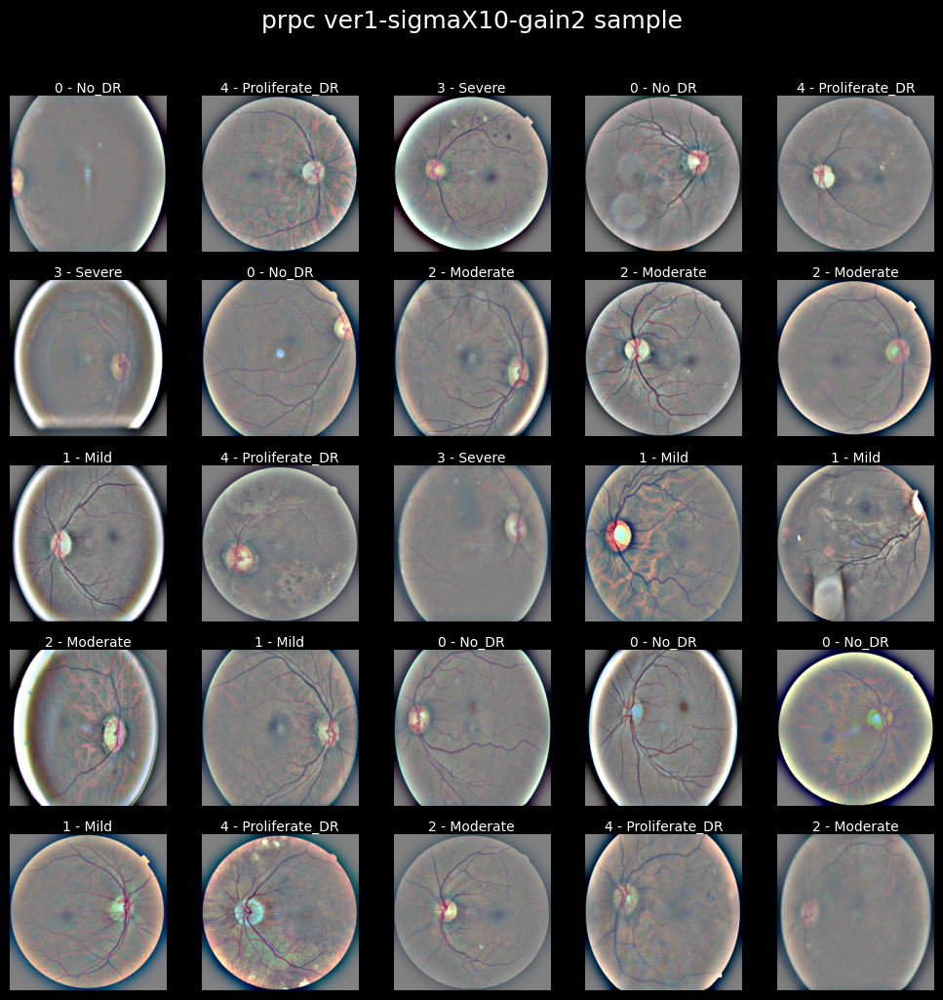

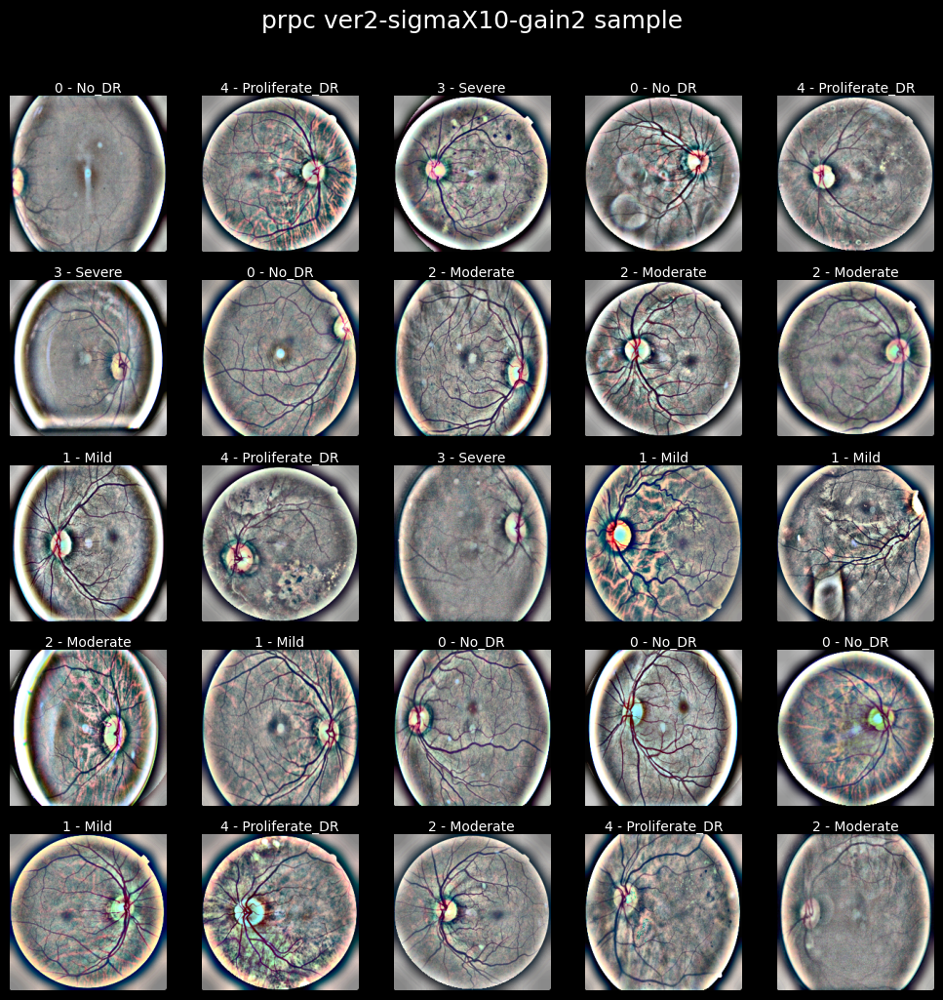

In [65]:
show_df_imgs(prpc_v1s10g2_df[:50],title="prpc ver1-sigmaX10-gain2 sample",fname="prpc_v1s10g2_sample.png",save=True)
show_df_imgs(prpc_v2s10g2_df[:50],title="prpc ver2-sigmaX10-gain2 sample",fname="prpc_v2s10g2_sample.png",save=True)

In [24]:
#After numerous attempts to process preprocessed dataset / dataframe which contains images, and fit it directly to model.fit(),
#failed too many times and had too much error so i decided save these preprocessed images first then reimport them as dataset, 
#which is much easier.

print(len(prpc_v1s10g2_df),len(prpc_v2s10g2_df))

3540 3540


In [ ]:
prpc_v1s10g2_df.head(),prpc_v2s10g2_df.head()

(                                               image  label
 0  [[[179, 179, 179], [179, 179, 179], [179, 179,...      0
 1  [[[156, 156, 156], [156, 156, 156], [156, 156,...      4
 2  [[[163, 163, 163], [163, 163, 163], [163, 163,...      3
 3  [[[151, 151, 151], [151, 151, 151], [151, 151,...      0
 4  [[[145, 145, 144], [145, 145, 144], [145, 145,...      4,
                                                image  label
 0  [[[128, 128, 128], [128, 128, 128], [128, 128,...      0
 1  [[[128, 128, 128], [128, 128, 128], [128, 128,...      4
 2  [[[128, 128, 128], [128, 128, 128], [128, 128,...      3
 3  [[[128, 128, 128], [128, 128, 128], [128, 128,...      0
 4  [[[128, 128, 128], [128, 128, 128], [128, 128,...      4)

In [26]:
save_preprocessed(df_ds=prpc_v1s10g2_df,folder_name = "prpc_ver1_sigmax10_gain2")
save_preprocessed(df_ds=prpc_v2s10g2_df,folder_name = "prpc_ver2_sigmax10_gain2")

Saved 3540 images into 'prpc_ver1_sigmax10_gain2' with 5 class folders.
Saved 3540 images into 'prpc_ver2_sigmax10_gain2' with 5 class folders.


In [27]:
save_preprocessed(df_ds=prpc_v1s10g2_val,folder_name = "val_prpc_ver1_sigmax10_gain2")
save_preprocessed(df_ds=prpc_v2s10g2_val,folder_name = "val_prpc_ver2_sigmax10_gain2")

Saved 1770 images into 'val_prpc_ver1_sigmax10_gain2' with 5 class folders.
Saved 1770 images into 'val_prpc_ver2_sigmax10_gain2' with 5 class folders.


## Let's build a simple CNN model to evaluate performance of each preprocessing methods

In [44]:
def get_model2(name="untitled_sequential",grayscale=False):
    color_channels = 3
    if grayscale :
        color_channels = 1
    model = tf.keras.Sequential([
            tf.keras.layers.Conv2D(32, (3,3), activation='relu', input_shape=(224, 224, color_channels)),
            tf.keras.layers.MaxPooling2D(2,2),
        
            tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
            tf.keras.layers.MaxPooling2D(2,2),
            
            tf.keras.layers.Conv2D(128, (3,3), activation='relu'),
            tf.keras.layers.MaxPooling2D(2,2),
            
            tf.keras.layers.Flatten(),
            tf.keras.layers.Dense(128, activation='relu'),
            tf.keras.layers.Dropout(0.5),
            tf.keras.layers.Dense(5, activation='softmax')
        ],name=name)
    model.compile(
        loss = tf.keras.losses.CategoricalCrossentropy(),
        optimizer = tf.keras.optimizers.Adam(learning_rate = 0.001),
        metrics = ['accuracy']
    )
    return model

In [29]:
tf.random.set_seed(42)
model_prpc_v1s10g2 = get_model2(name="prpc_v1s10g2")
model_prpc_v2s10g2 = get_model2(name="prpc_v2s10g2")

In [30]:
model_prpc_v1s10g2.summary()

Model: "prpc_v1s10g2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_6 (Conv2D)           (None, 222, 222, 32)      896       
                                                                 
 max_pooling2d_6 (MaxPooling  (None, 111, 111, 32)     0         
 2D)                                                             
                                                                 
 conv2d_7 (Conv2D)           (None, 109, 109, 64)      18496     
                                                                 
 max_pooling2d_7 (MaxPooling  (None, 54, 54, 64)       0         
 2D)                                                             
                                                                 
 conv2d_8 (Conv2D)           (None, 52, 52, 128)       73856     
                                                                 
 max_pooling2d_8 (MaxPooling  (None, 26, 26, 128)     

In [31]:
dsPrpc_v1s10g2 = tf.keras.utils.image_dataset_from_directory(
    "dataset/preprocessed_2/prpc_ver1_sigmax10_gain2",
    seed=42,
    batch_size=50,
    image_size=(224,224),
    label_mode="categorical"
)
dsPrpc_v2s10g2 = tf.keras.utils.image_dataset_from_directory(
    "dataset/preprocessed_2/prpc_ver2_sigmax10_gain2",
    seed=42,
    batch_size=50,
    image_size=(224,224),
    label_mode="categorical"
)

val_dsPrpc_v1s10g2 = tf.keras.utils.image_dataset_from_directory(
    "dataset/preprocessed_2/val_prpc_ver1_sigmax10_gain2",
    seed=42,
    batch_size=50,
    image_size=(224,224),
    label_mode="categorical"
)
val_dsPrpc_v2s10g2 = tf.keras.utils.image_dataset_from_directory(
    "dataset/preprocessed_2/val_prpc_ver2_sigmax10_gain2",
    seed=42,
    batch_size=50,
    image_size=(224,224),
    label_mode="categorical"
)

dsPrpc_v1s10g2,
dsPrpc_v2s10g2,
val_dsPrpc_v1s10g2,
val_dsPrpc_v2s10g2

Found 3540 files belonging to 5 classes.
Found 3540 files belonging to 5 classes.
Found 1770 files belonging to 5 classes.
Found 1770 files belonging to 5 classes.


<BatchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 5), dtype=tf.float32, name=None))>

255.0-0.0


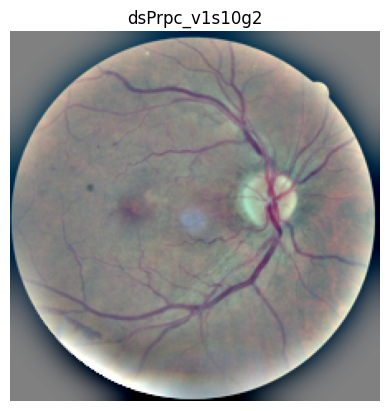

In [22]:
#Lets visualize some data to make sure they are correct
for b_imgs,b_labels in dsPrpc_v1s10g2.take(1):
    print(f"{np.max(b_imgs[1])}-{np.min(b_imgs[1])}")
    b_imgs = tf.cast(b_imgs,tf.uint8)
    plt.axis("off")
    plt.title("dsPrpc_v1s10g2")
    plt.imshow(b_imgs[1])
    break;

255.0-0.0


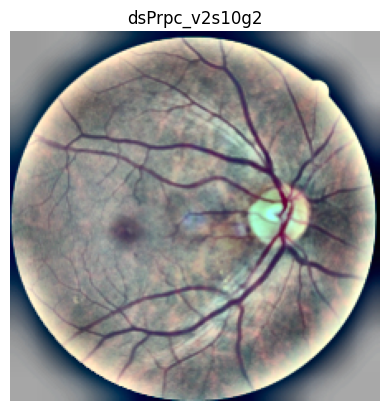

In [23]:
for b_imgs,b_labels in dsPrpc_v2s10g2.take(1):
    print(f"{np.max(b_imgs[1])}-{np.min(b_imgs[1])}")
    b_imgs = tf.cast(b_imgs,tf.uint8)
    plt.axis("off")
    plt.title("dsPrpc_v2s10g2")
    plt.imshow(b_imgs[1])
    break;

255.0-0.0


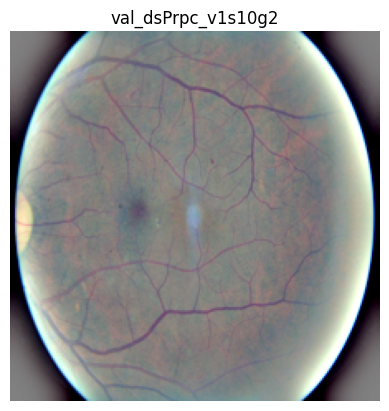

In [24]:
for b_imgs,b_labels in val_dsPrpc_v1s10g2.take(1):
    print(f"{np.max(b_imgs[1])}-{np.min(b_imgs[1])}")
    b_imgs = tf.cast(b_imgs,tf.uint8)
    plt.axis("off")
    plt.title("val_dsPrpc_v1s10g2")
    plt.imshow(b_imgs[1])
    break;

255.0-0.0


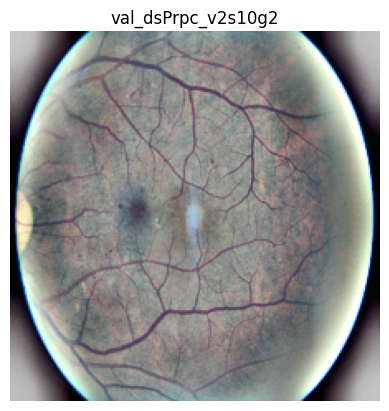

In [25]:
for b_imgs,b_labels in val_dsPrpc_v2s10g2.take(1):
    print(f"{np.max(b_imgs[1])}-{np.min(b_imgs[1])}")
    b_imgs = tf.cast(b_imgs,tf.uint8)
    plt.axis("off")
    plt.title("val_dsPrpc_v2s10g2")
    plt.imshow(b_imgs[1])
    break;

In [32]:
def normalize_img(imgs,labels):
    imgs = imgs/tf.reduce_max(imgs,axis=[0,1,2],keepdims=True)
    return tf.convert_to_tensor(imgs),tf.convert_to_tensor(labels)
dsPrpc_v1s10g2_N = dsPrpc_v1s10g2.map(normalize_img, num_parallel_calls = tf.data.AUTOTUNE)
dsPrpc_v2s10g2_N = dsPrpc_v2s10g2.map(normalize_img, num_parallel_calls = tf.data.AUTOTUNE)
val_dsPrpc_v1s10g2_N = dsPrpc_v1s10g2.map(normalize_img, num_parallel_calls = tf.data.AUTOTUNE)
val_dsPrpc_v2s10g2_N = dsPrpc_v2s10g2.map(normalize_img, num_parallel_calls = tf.data.AUTOTUNE)

In [33]:
dsPrpc_v1s10g2_N,dsPrpc_v1s10g2

(<ParallelMapDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 5), dtype=tf.float32, name=None))>,
 <BatchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 5), dtype=tf.float32, name=None))>)

In [ ]:
#Training models
tf.random.set_seed(42)
h_G1 = {}
h_G1["Model2-v1s10g2"] = model_prpc_v1s10g2.fit(dsPrpc_v1s10g2_N,validation_data = val_dsPrpc_v1s10g2_N, epochs=50,verbose = 1)

In [36]:
tf.random.set_seed(41)
h_G1["Model2-v2s10g2"] = model_prpc_v2s10g2.fit(dsPrpc_v2s10g2_N,validation_data = val_dsPrpc_v2s10g2_N, epochs=50,verbose = 1)

Epoch 1/50
71/71 [==============================] - 14s 187ms/step - loss: 1.6098 - accuracy: 0.1986 - val_loss: 1.6094 - val_accuracy: 0.2000
Epoch 2/50
71/71 [==============================] - 14s 182ms/step - loss: 1.6098 - accuracy: 0.2056 - val_loss: 1.6094 - val_accuracy: 0.2017
Epoch 3/50
71/71 [==============================] - 14s 181ms/step - loss: 1.6109 - accuracy: 0.1989 - val_loss: 1.6094 - val_accuracy: 0.2008
Epoch 4/50
71/71 [==============================] - 14s 178ms/step - loss: 1.6098 - accuracy: 0.1907 - val_loss: 1.6076 - val_accuracy: 0.2034
Epoch 5/50
71/71 [==============================] - 14s 184ms/step - loss: 1.6097 - accuracy: 0.2105 - val_loss: 1.6067 - val_accuracy: 0.2260
Epoch 6/50
71/71 [==============================] - 14s 182ms/step - loss: 1.6112 - accuracy: 0.2023 - val_loss: 1.6085 - val_accuracy: 0.2107
Epoch 7/50
71/71 [==============================] - 14s 181ms/step - loss: 1.6082 - accuracy: 0.2023 - val_loss: 1.6053 - val_accuracy: 0.2161

In [37]:
m2v1s10g2_eval = model_prpc_v1s10g2.evaluate(val_dsPrpc_v1s10g2_N)
m2v2s10g2_eval = model_prpc_v2s10g2.evaluate(val_dsPrpc_v2s10g2_N)

71/71 [==============================] - 5s 58ms/step - loss: 0.1513 - accuracy: 0.9706


In [38]:
m2v2s10g2_eval[0],m2v1s10g2_eval[0]

(0.15133261680603027, 0.06088341772556305)

In [39]:
if m2v2s10g2_eval[0]-m2v1s10g2_eval[0] > 0:
    print("m2v2s10g2's loss > m2v1s10g2's loss")
elif m2v2s10g2_eval[0]-m2v1s10g2_eval[0] < 0:
    print("m2v2s10g2's loss < m2v1s10g2's loss")
else :
    print("Equal")

m2v2s10g2's loss > m2v1s10g2's loss


#### PLot the evaluation of 2 preprocessed data

In [40]:
# Prepare the history DataFrame
def plot_modelMetrics(h,title="model metrics",fname="model_metrics.png"):
    df = pd.DataFrame(h.history)
    num_epochs = len(df)
    step       = max(1, num_epochs // 10)
    positions  = list(range(0, num_epochs, step))
    
    # Dark background style
    plt.style.use('dark_background')
    fig, (ax1, ax2) = plt.subplots(
        1, 2,
        figsize=(14, 6),
        dpi=300,
        facecolor='black'
    )
    for ax in (ax1, ax2):
        ax.set_facecolor('black')
        ax.grid(True, color='#555555', linestyle='--', linewidth=0.5)
    
    # ─── Accuracy subplot ────────────────────────────────────────────
    ax1.plot(
        df['accuracy'],marker="x",markersize=4, linewidth=1, color='#39FF14',
        label='Train Acc'
    )
    ax1.plot(
        df['val_accuracy'],marker="x",markersize=4,linewidth=1, color='#FF0090',
        label='Val Acc'
    )
    ax1.set_title('Accuracy', color='#39FF14', fontsize=16, pad=10)
    ax1.set_xlabel('Epoch', color='#39FF14')
    ax1.set_ylabel('Accuracy', color='#39FF14')
    ax1.set_ylim(0, 1)
    ax1.set_xticks(positions)
    ax1.set_xticklabels(positions, rotation=45, color='#39FF14')
    ax1.tick_params(axis='y', colors='#39FF14')
    leg1 = ax1.legend(facecolor='black', edgecolor='#39FF14')
    for text in leg1.get_texts(): text.set_color('#39FF14')
    
    # ─── Loss subplot ─────────────────────────────────────────────────
    ax2.plot(
        df['loss'],marker="x",markersize=4 ,linewidth=1, color='#00FFFF',
        label='Train Loss'
    )
    ax2.plot(
        df['val_loss'],marker="x",markersize=4, linewidth=1, color='#FFA500',
        label='Val Loss'
    )
    ax2.set_title('Loss', color='#00FFFF', fontsize=16, pad=10)
    ax2.set_xlabel('Epoch', color='#00FFFF')
    ax2.set_ylabel('Loss', color='#00FFFF')
    # autoscale y to data range, with a little padding
    ymin = df[['loss','val_loss']].min().min() * 0.9
    ymax = df[['loss','val_loss']].max().max() * 1.1
    ax2.set_ylim(ymin, ymax)
    ax2.set_xticks(positions)
    ax2.set_xticklabels(positions, rotation=45, color='#00FFFF')
    ax2.tick_params(axis='y', colors='#00FFFF')
    leg2 = ax2.legend(facecolor='black', edgecolor='#00FFFF')
    for text in leg2.get_texts(): text.set_color('#00FFFF')
    
    # Supertitle and layout
    fig.suptitle(title, color='white', fontsize=18, y=1.02)
    plt.tight_layout()
    
    # Display
    plt.show()
    
    # Save the figure
    fig.savefig(
        fname,
        dpi=300,
        facecolor=fig.get_facecolor(),
        edgecolor='black',
        bbox_inches='tight'
    )


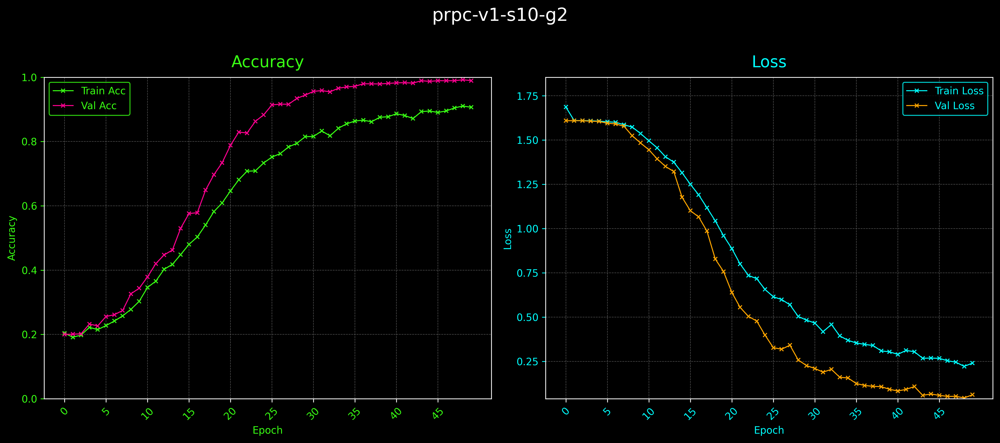

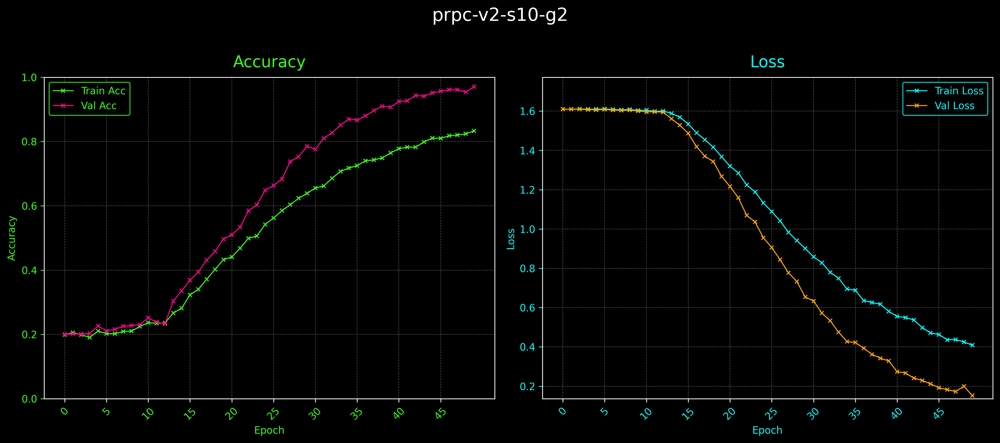

In [42]:
plot_modelMetrics(h=h_G1["Model2-v1s10g2"],title="prpc-v1-s10-g2",fname="prpc_v1s10g2_eval_graph.png")
plot_modelMetrics(h=h_G1["Model2-v2s10g2"],title="prpc-v2-s10-g2",fname="prpc_v2s10g2_eval_graph.png")

### We noticed that the evaluation of both preprocessed data are in fact very close, but ver1s10g2 still yielded higher accuracy: 0.9941 vs accuracy: 0.9749, therefore we will be continue testing version 1 with different SigmaX parameter and Gain
##### [ver1 - sigmaX10 - Gain2] vs [ver1 - sigmaX10 - Gain4]

In [91]:
#we will be now testing Model2v1s10g4
prpc_v1s10g4_df = df_ds.copy(deep =True)
prpc_v1s10g4_df["image"] = prpc_v1s10g4_df["image"].apply(lambda i:preprocessing_1(img=i,sigmaX=10,gain=4))

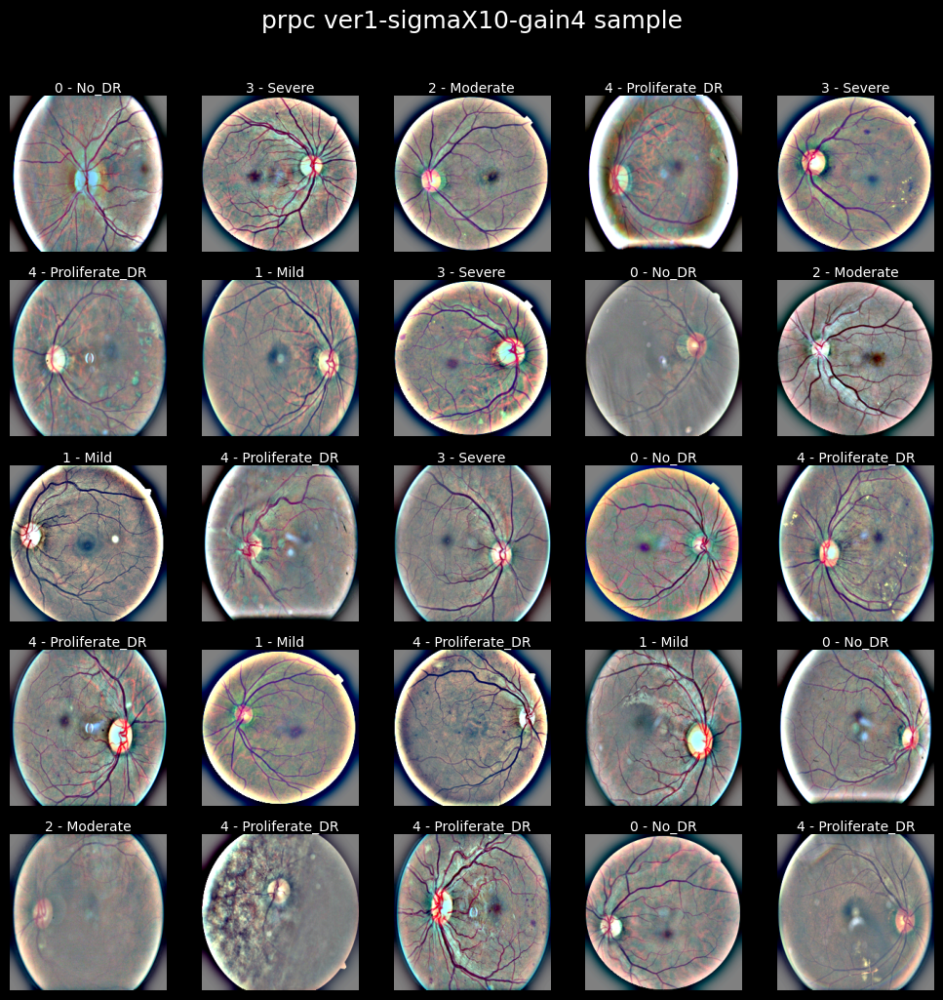

In [103]:
show_df_imgs(prpc_v1s10g4_df[:50],title="prpc ver1-sigmaX10-gain4 sample",fname="prpc_v1s10g4.png",save=True)

In [106]:
prpc_v1s10g4_val = df_ds_val.copy(deep=True)
prpc_v1s10g4_val["image"] = prpc_v1s10g4_val["image"].apply(lambda i:preprocessing_1(img=i,sigmaX=10,gain=4))

In [109]:
save_preprocessed(df_ds=prpc_v1s10g4_df,folder_name = "prpc_ver1_sigmax10_gain4")
save_preprocessed(df_ds=prpc_v1s10g4_val,folder_name = "val_prpc_ver1_sigmax10_gain4")

Saved 3540 images into 'prpc_ver2_sigmax10_gain4' with 5 class folders.
Saved 1770 images into 'val_prpc_ver2_sigmax10_gain4' with 5 class folders.


In [124]:
prpc_v1s10g4_trainds = tf.keras.utils.image_dataset_from_directory(
    "dataset/preprocessed_2/prpc_ver1_sigmax10_gain4",
    seed=42,
    batch_size=50,
    image_size=(224,224),
    label_mode="categorical"
)
prpc_v1s10g4_valds = tf.keras.utils.image_dataset_from_directory(
    "dataset/preprocessed_2/val_prpc_ver1_sigmax10_gain4",
    seed=42,
    batch_size=50,
    image_size=(224,224),
    label_mode="categorical"
)


Found 3540 files belonging to 5 classes.
Found 1770 files belonging to 5 classes.


In [126]:
prpc_v1s10g4_trainds_N = prpc_v1s10g4_trainds.map(normalize_img,num_parallel_calls =tf.data.AUTOTUNE)
prpc_v1s10g4_valds_N = prpc_v1s10g4_valds.map(normalize_img,num_parallel_calls=tf.data.AUTOTUNE)

In [129]:
models_G1=[]
models_G1.append(get_model2(name="Model2-v1s10g4"))
h_G1["Model2-v1s10g4"] = models_G1[0].fit(
    prpc_v1s10g4_trainds_N,
    epochs=50,
    validation_data = prpc_v1s10g4_valds_N,
    verbose=1
)

Epoch 1/50
71/71 [==============================] - 20s 256ms/step - loss: 1.6864 - accuracy: 0.2011 - val_loss: 1.6092 - val_accuracy: 0.2000
Epoch 2/50
71/71 [==============================] - 16s 218ms/step - loss: 1.6095 - accuracy: 0.2028 - val_loss: 1.6085 - val_accuracy: 0.2198
Epoch 3/50
71/71 [==============================] - 17s 224ms/step - loss: 1.6107 - accuracy: 0.2023 - val_loss: 1.6072 - val_accuracy: 0.2209
Epoch 4/50
71/71 [==============================] - 17s 218ms/step - loss: 1.6053 - accuracy: 0.2339 - val_loss: 1.6048 - val_accuracy: 0.2322
Epoch 5/50
71/71 [==============================] - 18s 237ms/step - loss: 1.6043 - accuracy: 0.2345 - val_loss: 1.6010 - val_accuracy: 0.2610
Epoch 6/50
71/71 [==============================] - 17s 231ms/step - loss: 1.5914 - accuracy: 0.2627 - val_loss: 1.5905 - val_accuracy: 0.2746
Epoch 7/50
71/71 [==============================] - 18s 248ms/step - loss: 1.5731 - accuracy: 0.2853 - val_loss: 1.5612 - val_accuracy: 0.3192

##### after observation of ver1 sigmaX10 gain4, we conclude that higher gain might increase noises in the data, which explain model overfitting on training data with noises and perform poorly on validation dataset

In [131]:
models_G1[0].evaluate(prpc_v1s10g4_valds_N)

36/36 [==============================] - 5s 114ms/step - loss: 2.7184 - accuracy: 0.6141


[2.7183985710144043, 0.6141242980957031]

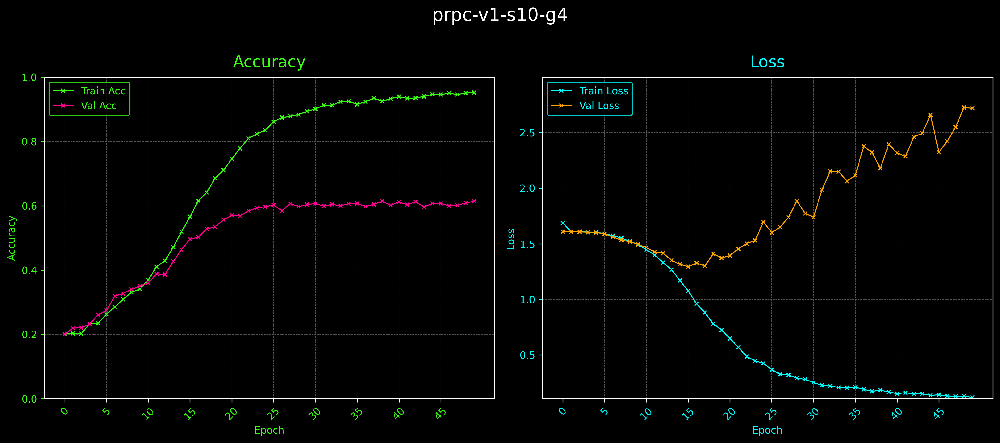

In [130]:
plot_modelMetrics(h=h_G1["Model2-v1s10g4"],title="prpc-v1-s10-g4",fname="prpc-v1-s10-g4.png")

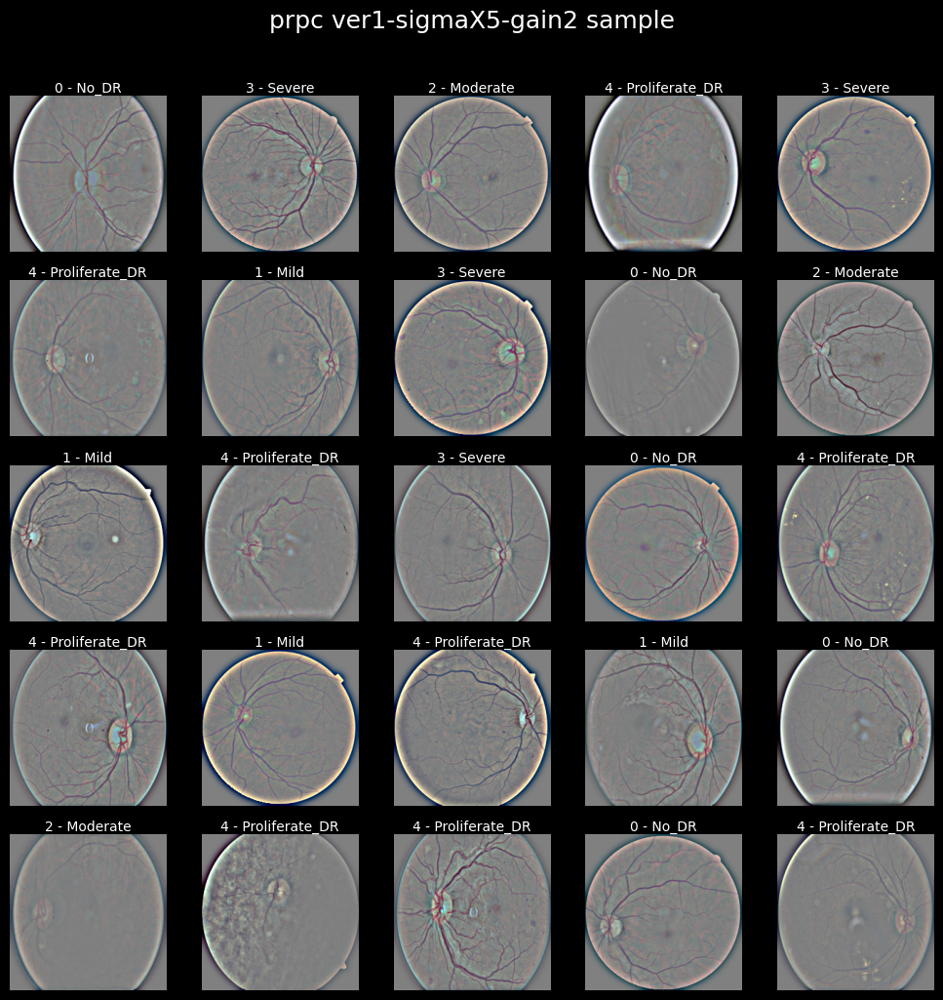

In [132]:
#lets now test ver1 sigmax5 gain2
prpc_v1s5g2_df = df_ds.copy(deep =True)
prpc_v1s5g2_df["image"] = prpc_v1s5g2_df["image"].apply(lambda i:preprocessing_1(img=i,sigmaX=5,gain=2))
prpc_v1s5g2_val = df_ds_val.copy(deep=True)
prpc_v1s5g2_val["image"] = prpc_v1s5g2_val["image"].apply(lambda i:preprocessing_1(img=i,sigmaX=5,gain=2))


show_df_imgs(prpc_v1s5g2_df[:50],title="prpc ver1-sigmaX5-gain2 sample",fname="prpc_v1s5g2.png",save=True)

In [133]:
save_preprocessed(df_ds=prpc_v1s5g2_df,folder_name = "prpc_ver1_sigmax5_gain2")
save_preprocessed(df_ds=prpc_v1s5g2_val,folder_name = "val_prpc_ver1_sigmax5_gain2")

Saved 3540 images into 'prpc_ver1_sigmax5_gain2' with 5 class folders.
Saved 1770 images into 'val_prpc_ver1_sigmax5_gain2' with 5 class folders.


In [134]:
prpc_v1s5g2_trainds = tf.keras.utils.image_dataset_from_directory(
    "dataset/preprocessed_2/prpc_ver1_sigmax5_gain2",
    seed=42,
    batch_size=50,
    image_size=(224,224),
    label_mode="categorical"
)
prpc_v1s5g2_valds = tf.keras.utils.image_dataset_from_directory(
    "dataset/preprocessed_2/val_prpc_ver1_sigmax5_gain2",
    seed=42,
    batch_size=50,
    image_size=(224,224),
    label_mode="categorical"
)

Found 3540 files belonging to 5 classes.
Found 1770 files belonging to 5 classes.


In [135]:
prpc_v1s5g2_trainds_N = prpc_v1s5g2_trainds.map(normalize_img,num_parallel_calls =tf.data.AUTOTUNE)
prpc_v1s5g2_valds_N = prpc_v1s5g2_valds.map(normalize_img,num_parallel_calls=tf.data.AUTOTUNE)

In [146]:
prpc_v1s10g4_trainds_N,prpc_v1s5g2_trainds_N

(<ParallelMapDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 5), dtype=tf.float32, name=None))>,
 <ParallelMapDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 5), dtype=tf.float32, name=None))>)

In [147]:
tf.random.set_seed(42)
model = get_model2()
h_G1["Model2-v1s5g2"] = model.fit(
    prpc_v1s5g2_trainds_N,
    epochs=50,
    validation_data = prpc_v1s5g2_valds_N,
    verbose=1
)

Epoch 1/50
71/71 [==============================] - 19s 226ms/step - loss: 1.6777 - accuracy: 0.2017 - val_loss: 1.6093 - val_accuracy: 0.2028
Epoch 2/50
71/71 [==============================] - 18s 232ms/step - loss: 1.6103 - accuracy: 0.2119 - val_loss: 1.6088 - val_accuracy: 0.2345
Epoch 3/50
71/71 [==============================] - 16s 215ms/step - loss: 1.6099 - accuracy: 0.1836 - val_loss: 1.6094 - val_accuracy: 0.2000
Epoch 4/50
71/71 [==============================] - 18s 236ms/step - loss: 1.6095 - accuracy: 0.1907 - val_loss: 1.6094 - val_accuracy: 0.2051
Epoch 5/50
71/71 [==============================] - 19s 243ms/step - loss: 1.6096 - accuracy: 0.1879 - val_loss: 1.6094 - val_accuracy: 0.2011
Epoch 6/50
71/71 [==============================] - 19s 247ms/step - loss: 1.6094 - accuracy: 0.1876 - val_loss: 1.6094 - val_accuracy: 0.2000
Epoch 7/50
71/71 [==============================] - 18s 236ms/step - loss: 1.6096 - accuracy: 0.1952 - val_loss: 1.6095 - val_accuracy: 0.2000

In [150]:
model.evaluate(prpc_v1s5g2_valds_N)

36/36 [==============================] - 5s 103ms/step - loss: 1.4084 - accuracy: 0.5469


[1.408435344696045, 0.5468926429748535]

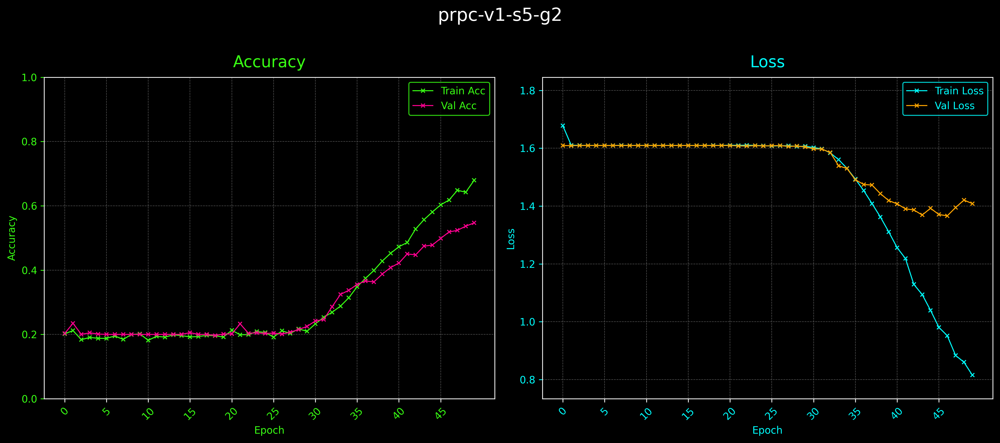

In [149]:
plot_modelMetrics(h=h_G1["Model2-v1s5g2"],title="prpc-v1-s5-g2",fname="prpc-v1-s5-g2.png")

### After our evaluation between different settings(sigmaX,version,gain), We concluded that the best settings are version2,sigmaX10,gain2
### Let's do our final testing between grayscale and rgb

In [75]:
tf.random.set_seed(42)
model_grayscale = get_model2(name="model_grayscale",grayscale=True)
model_grayscale.summary()

Model: "model_grayscale"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_27 (Conv2D)          (None, 222, 222, 32)      320       
                                                                 
 max_pooling2d_27 (MaxPoolin  (None, 111, 111, 32)     0         
 g2D)                                                            
                                                                 
 conv2d_28 (Conv2D)          (None, 109, 109, 64)      18496     
                                                                 
 max_pooling2d_28 (MaxPoolin  (None, 54, 54, 64)       0         
 g2D)                                                            
                                                                 
 conv2d_29 (Conv2D)          (None, 52, 52, 128)       73856     
                                                                 
 max_pooling2d_29 (MaxPoolin  (None, 26, 26, 128)  

In [76]:
def grayscale(img,label):
    gray = tf.image.rgb_to_grayscale(img)
    return gray, label

In [77]:
dsPrpc_v1s10g2_grscl = dsPrpc_v1s10g2.map(grayscale,num_parallel_calls= tf.data.AUTOTUNE)
val_dsPrpc_v1s10g2_grscl = dsPrpc_v1s10g2.map(grayscale, num_parallel_calls = tf.data.AUTOTUNE)

In [78]:
dsPrpc_v1s10g2_N_grscl,val_dsPrpc_v1s10g2_N_grscl

(<ParallelMapDataset element_spec=(TensorSpec(shape=(None, 224, 224, 1), dtype=tf.float32, name=None), TensorSpec(shape=(None, 5), dtype=tf.float32, name=None))>,
 <ParallelMapDataset element_spec=(TensorSpec(shape=(None, 224, 224, 1), dtype=tf.float32, name=None), TensorSpec(shape=(None, 5), dtype=tf.float32, name=None))>)

254.97451782226562-2.928799867630005


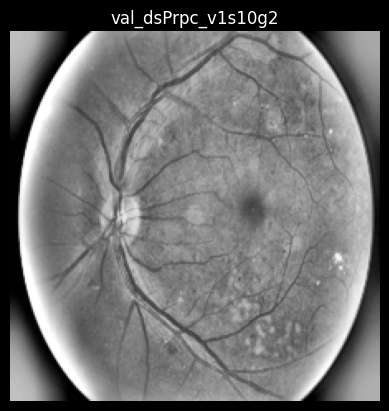

In [79]:
for b_imgs,b_labels in dsPrpc_v1s10g2_grscl.take(1):
    print(f"{np.max(b_imgs[1])}-{np.min(b_imgs[1])}")
    b_imgs = tf.cast(b_imgs,tf.uint8)
    plt.axis("off")
    plt.title("val_dsPrpc_v1s10g2")
    plt.imshow(b_imgs[1],cmap="gray")
    break;

In [80]:
dsPrpc_v1s10g2_grscl_N = dsPrpc_v1s10g2_grscl.map(normalize_img,num_parallel_calls= tf.data.AUTOTUNE)
val_dsPrpc_v1s10g2_grscl_N = val_dsPrpc_v1s10g2_grscl.map(normalize_img, num_parallel_calls = tf.data.AUTOTUNE)

In [81]:
h_G1["Model2-v1s10g2-grscl"] = model_grayscale.fit(dsPrpc_v1s10g2_grscl_N,validation_data=val_dsPrpc_v1s10g2_grscl_N,
                   epochs=50,verbose=1)

Epoch 1/50
71/71 [==============================] - 57s 182ms/step - loss: 1.6321 - accuracy: 0.1918 - val_loss: 1.6094 - val_accuracy: 0.2000
Epoch 2/50
71/71 [==============================] - 13s 170ms/step - loss: 1.6095 - accuracy: 0.2071 - val_loss: 1.6093 - val_accuracy: 0.2040
Epoch 3/50
71/71 [==============================] - 12s 157ms/step - loss: 1.6090 - accuracy: 0.2008 - val_loss: 1.6538 - val_accuracy: 0.2000
Epoch 4/50
71/71 [==============================] - 11s 149ms/step - loss: 1.6139 - accuracy: 0.1831 - val_loss: 1.6095 - val_accuracy: 0.2000
Epoch 5/50
71/71 [==============================] - 13s 167ms/step - loss: 1.6097 - accuracy: 0.2042 - val_loss: 1.6095 - val_accuracy: 0.2000
Epoch 6/50
71/71 [==============================] - 13s 166ms/step - loss: 1.6099 - accuracy: 0.1864 - val_loss: 1.6094 - val_accuracy: 0.2000
Epoch 7/50
71/71 [==============================] - 12s 167ms/step - loss: 1.6096 - accuracy: 0.1938 - val_loss: 1.6094 - val_accuracy: 0.2000

In [85]:
model_grayscale.evaluate(val_dsPrpc_v1s10g2_grscl_N)

71/71 [==============================] - 4s 49ms/step - loss: 0.0047 - accuracy: 0.9994


[0.004740241449326277, 0.9994350075721741]

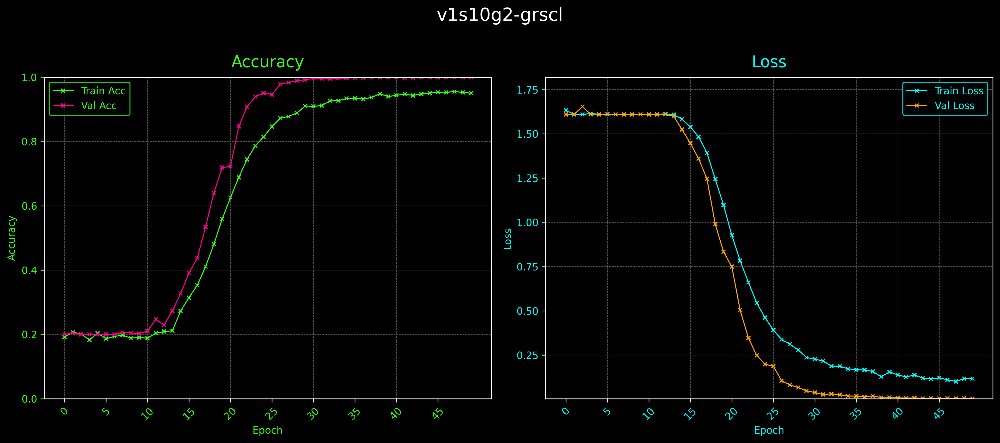

In [82]:
plot_modelMetrics(h=h_G1["Model2-v1s10g2-grscl"],title="v1s10g2-grscl",fname="prpc_v1s10g2_grscl_eval_graph.png")

## In conclusion, the result difference between (settings sigmaX10, gain2) version 1,2,grayscaled are NUANCED, we will be select 4 best performers preprocessed dataset which are ver1,2 (sigmax10,gain2) and grayscaled version of these two for bigger dataset testing.

In [ ]:
#now let's save the grayscaled versions


In [72]:
#cloning dataset for testing each preprocessing methods and directly feed to simple model to check result 
prpc_v1s10g2_grscl_df = df_ds.copy(deep=True) 
prpc_v2s10g2_grscl_df = df_ds.copy(deep=True) 
prpc_v1s10g2_grscl_df["image"] = prpc_v1s10g2_grscl_df["image"].apply(lambda x : preprocessing_1(x,sigmaX=10,gain=2)) 
prpc_v2s10g2_grscl_df["image"] = prpc_v2s10g2_grscl_df["image"].apply(lambda x : preprocessing_2(x,sigmaX=10,gain=2))  

#preparing validation data 
prpc_v1s10g2_grscl_valdf = df_ds_val.copy(deep=True) 
prpc_v2s10g2_grscl_valdf = df_ds_val.copy(deep=True) 
prpc_v1s10g2_grscl_valdf["image"] = prpc_v1s10g2_grscl_valdf["image"].apply(lambda x : preprocessing_1(x,sigmaX=10,gain=2)) 
prpc_v2s10g2_grscl_valdf["image"] = prpc_v2s10g2_grscl_valdf["image"].apply(lambda x : preprocessing_2(x,sigmaX=10,gain=2))  

In [73]:
prpc_v1s10g2_grscl_df["image"] = prpc_v1s10g2_grscl_df["image"].apply(
    lambda im: cv2.cvtColor(im, cv2.COLOR_RGB2GRAY)
)
prpc_v2s10g2_grscl_df["image"] = prpc_v2s10g2_grscl_df["image"].apply(
    lambda im: cv2.cvtColor(im, cv2.COLOR_RGB2GRAY)
)

In [74]:
prpc_v1s10g2_grscl_valdf["image"] = prpc_v1s10g2_grscl_valdf["image"].apply(
    lambda im: cv2.cvtColor(im, cv2.COLOR_RGB2GRAY)
)
prpc_v2s10g2_grscl_valdf["image"] = prpc_v2s10g2_grscl_valdf["image"].apply(
    lambda im: cv2.cvtColor(im, cv2.COLOR_RGB2GRAY)
)

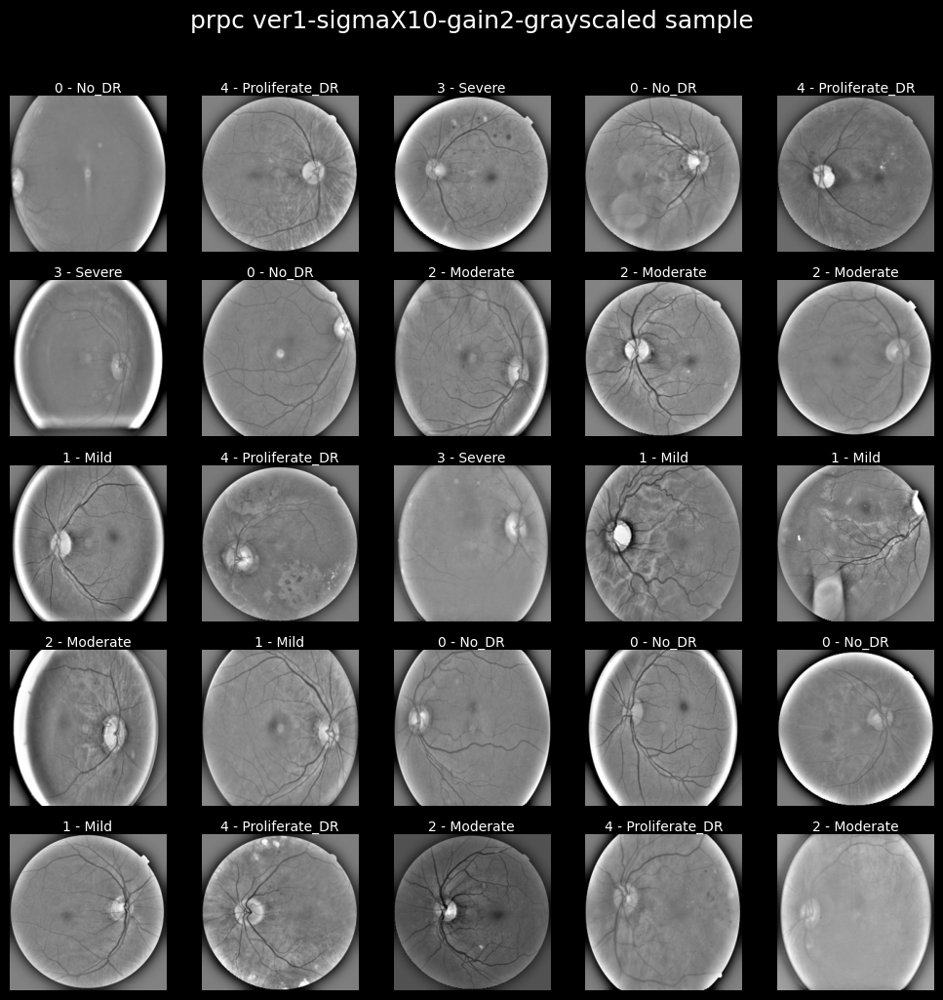

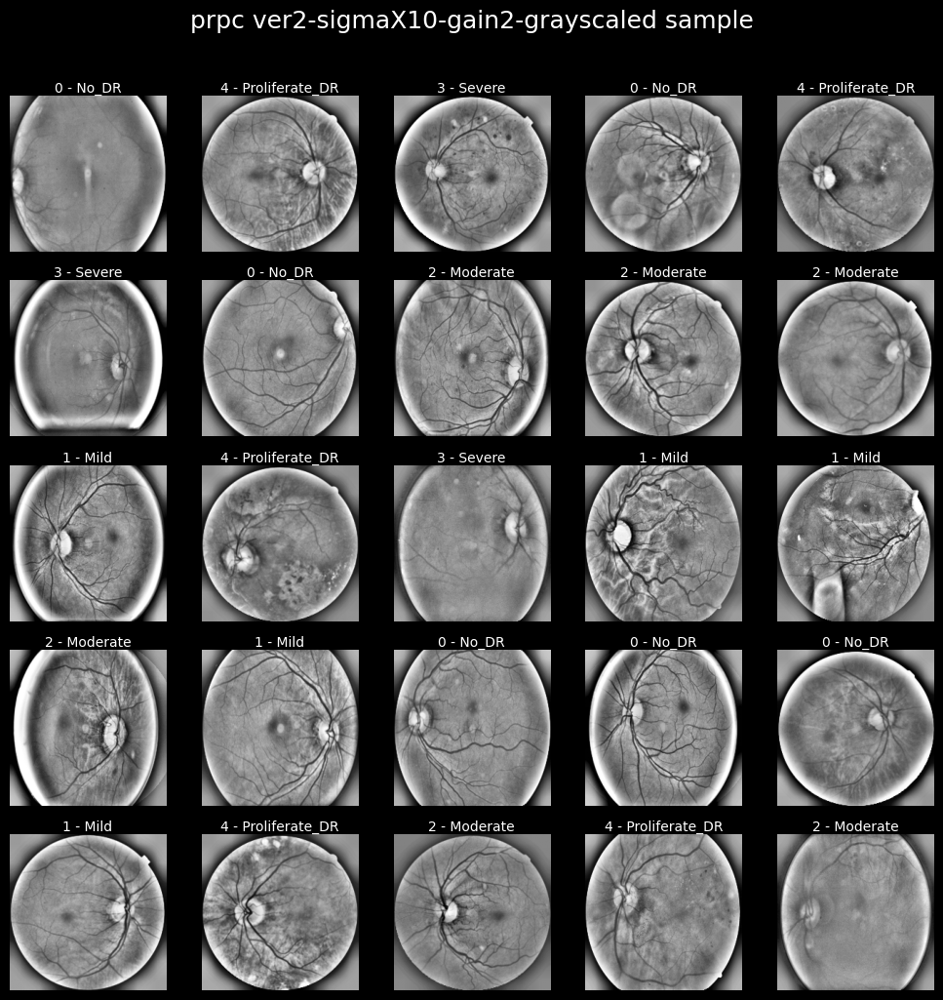

In [75]:
show_df_imgs(prpc_v1s10g2_grscl_df[:50],title="prpc ver1-sigmaX10-gain2-grayscaled sample",grayscale=True,fname="prpc_v1s10g2_grscl_sample.png",save=True)
show_df_imgs(prpc_v2s10g2_grscl_df[:50],title="prpc ver2-sigmaX10-gain2-grayscaled sample",grayscale=True,fname="prpc_v2s10g2_grscl_sample.png",save=True)

In [97]:
save_preprocessed(df_ds=prpc_v1s10g2_grscl_df,
                  folder_name = "prpc_ver1_sigmax10_gain2_grscl")

save_preprocessed(df_ds=prpc_v2s10g2_grscl_df,
                  folder_name = "prpc_ver2_sigmax10_gain2_grscl")

save_preprocessed(df_ds=prpc_v1s10g2_grscl_valdf,
                  folder_name = "val_prpc_ver1_sigmax10_gain2_grscl")

save_preprocessed(df_ds=prpc_v2s10g2_grscl_valdf,
                  folder_name = "val_prpc_ver2_sigmax10_gain2_grscl")

Saved 3540 images into 'prpc_ver1_sigmax10_gain2_grscl' with 5 class folders.
Saved 3540 images into 'prpc_ver2_sigmax10_gain2_grscl' with 5 class folders.
Saved 1770 images into 'val_prpc_ver1_sigmax10_gain2_grscl' with 5 class folders.
Saved 1770 images into 'val_prpc_ver2_sigmax10_gain2_grscl' with 5 class folders.


## Don't need to read after this line, most of the code below are "Brouillon" to test different things, I eventually picked preprocessed_2 (CLACHE applied to prpc 1) with black masked, meaning a color RGB retina with a black background

In [9]:
#let's get a big validation dataset for monte carlo estimation
df_val_complete = pd.read_csv(f"{os.getcwd()}/dataset/kaggle_ds/tanlikesmath/diabetic-retinopathy-resized/versions/7/trainLabels_cropped.csv")

In [23]:
df_val_complete.head(),len(df_val_complete)

(   Unnamed: 0.1  Unnamed: 0     image  level
 0             0           0   10_left      0
 1             1           1  10_right      0
 2             2           2   13_left      0
 3             3           3  13_right      0
 4             4           4   15_left      1,
 35108)

In [24]:
df_val_complete.columns

Index(['Unnamed: 0.1', 'Unnamed: 0', 'image', 'level'], dtype='object')

In [25]:
df_val_complete = df_val_complete.drop(["Unnamed: 0.1","Unnamed: 0"],axis=1)
df_val_complete.columns

Index(['image', 'level'], dtype='object')

In [22]:
df_val_complete.head()

,image,level
0,10_left,0
1,10_right,0
2,13_left,0
3,13_right,0
4,15_left,1


In [26]:
df_val_complete = load_paths(df_val_complete,f"/dataset/kaggle_ds/tanlikesmath/diabetic-retinopathy-resized/versions/7/resized_train_cropped")

In [27]:
df_val_complete.head()

,path,image,level
0,C:\Users\thaim\Documents\Machine learning/data...,10003_left,0
1,C:\Users\thaim\Documents\Machine learning/data...,10003_right,0
2,C:\Users\thaim\Documents\Machine learning/data...,10007_left,0
3,C:\Users\thaim\Documents\Machine learning/data...,10007_right,0
4,C:\Users\thaim\Documents\Machine learning/data...,10009_left,0


In [28]:
df_val_complete["path"] = df_val_complete["path"].apply(lambda p : load_img(path=p,size=(224,224)))

In [30]:
len(df_val_complete)

35108

In [35]:
df_val_sample = df_val_complete.sample(n=17000, random_state=42)

In [39]:
df_val_sample.head()

,path,image,level
13810,"[[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...",25737_left,0
22083,"[[[0, 0, 0], [1, 1, 1], [1, 1, 1], [0, 0, 0], ...",35246_right,0
27552,"[[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...",41335_right,2
15987,"[[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...",28181_right,0
16171,"[[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...",283_right,2


In [82]:
df_val_sample.drop("image",axis=1,inplace=True),df_val_sample.rename(columns={"path":"image"},inplace=True)

(None, None)

In [83]:
df_val_sample.head()

,image,level
13810,"[[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...",0
22083,"[[[0, 0, 0], [1, 1, 1], [1, 1, 1], [0, 0, 0], ...",0
27552,"[[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...",2
15987,"[[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...",0
16171,"[[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...",2


In [102]:
val_prpc_v1g10g2 = df_val_sample.copy(deep=True)
val_prpc_v2g10g2 = df_val_sample.copy(deep=True)

val_prpc_v1g10g2_grscl = df_val_sample.copy(deep=True)
val_prpc_v2g10g2_grscl = df_val_sample.copy(deep=True)

In [103]:
val_prpc_v1g10g2["image"] = val_prpc_v1g10g2["image"].apply(lambda x : preprocessing_1(x,sigmaX=10,gain=2))
val_prpc_v2g10g2["image"] = val_prpc_v2g10g2["image"].apply(lambda x : preprocessing_2(x,sigmaX=10,gain=2))

In [104]:
val_prpc_v1g10g2.rename(columns={"level":"label"},inplace=True)
val_prpc_v2g10g2.rename(columns={"level":"label"},inplace=True)

In [105]:
val_prpc_v1g10g2.columns

Index(['image', 'label'], dtype='object')

In [106]:
val_prpc_v1g10g2_grscl = val_prpc_v1g10g2.copy(deep=True)
val_prpc_v2g10g2_grscl = val_prpc_v2g10g2.copy(deep=True)
val_prpc_v1g10g2_grscl["image"] = val_prpc_v1g10g2["image"].apply(
    lambda im: cv2.cvtColor(im, cv2.COLOR_RGB2GRAY)
)
val_prpc_v2g10g2_grscl["image"] = val_prpc_v2g10g2["image"].apply(
    lambda im: cv2.cvtColor(im, cv2.COLOR_RGB2GRAY)
)

                                                                            

In [107]:
val_prpc_v1g10g2_grscl.columns,val_prpc_v2g10g2_grscl.columns

(Index(['image', 'label'], dtype='object'),
 Index(['image', 'label'], dtype='object'))

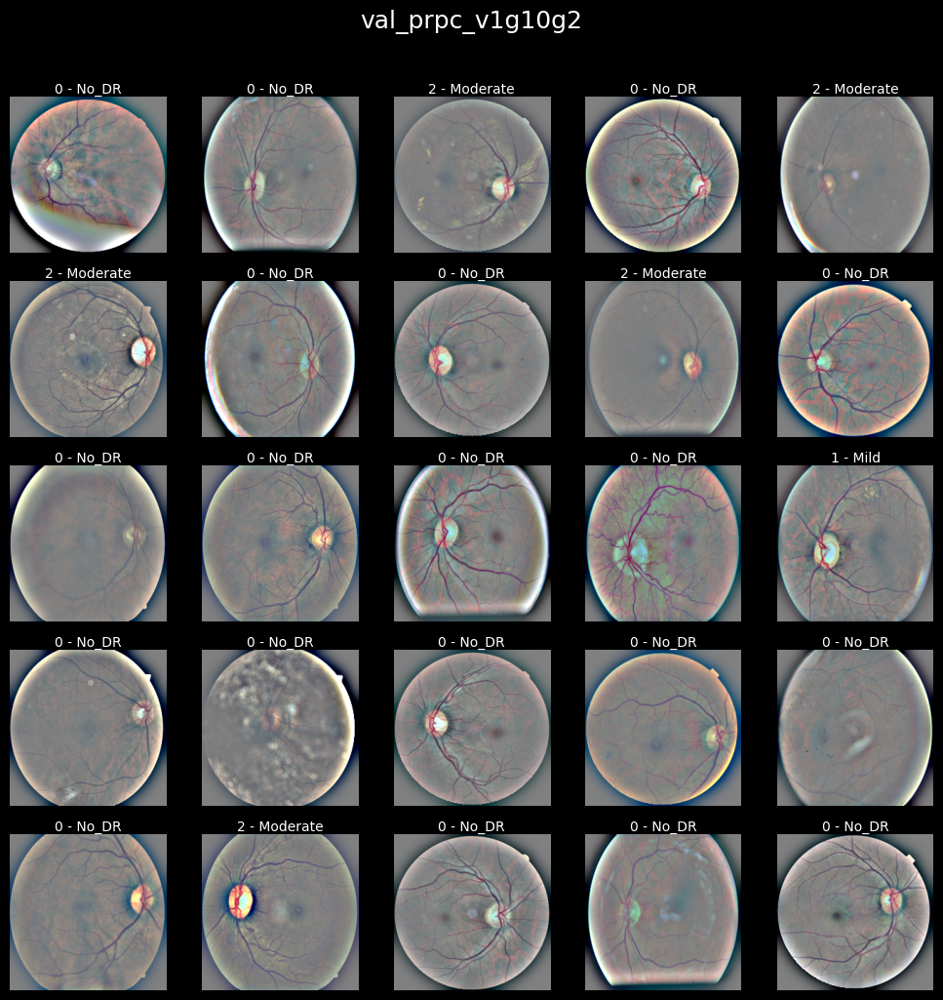

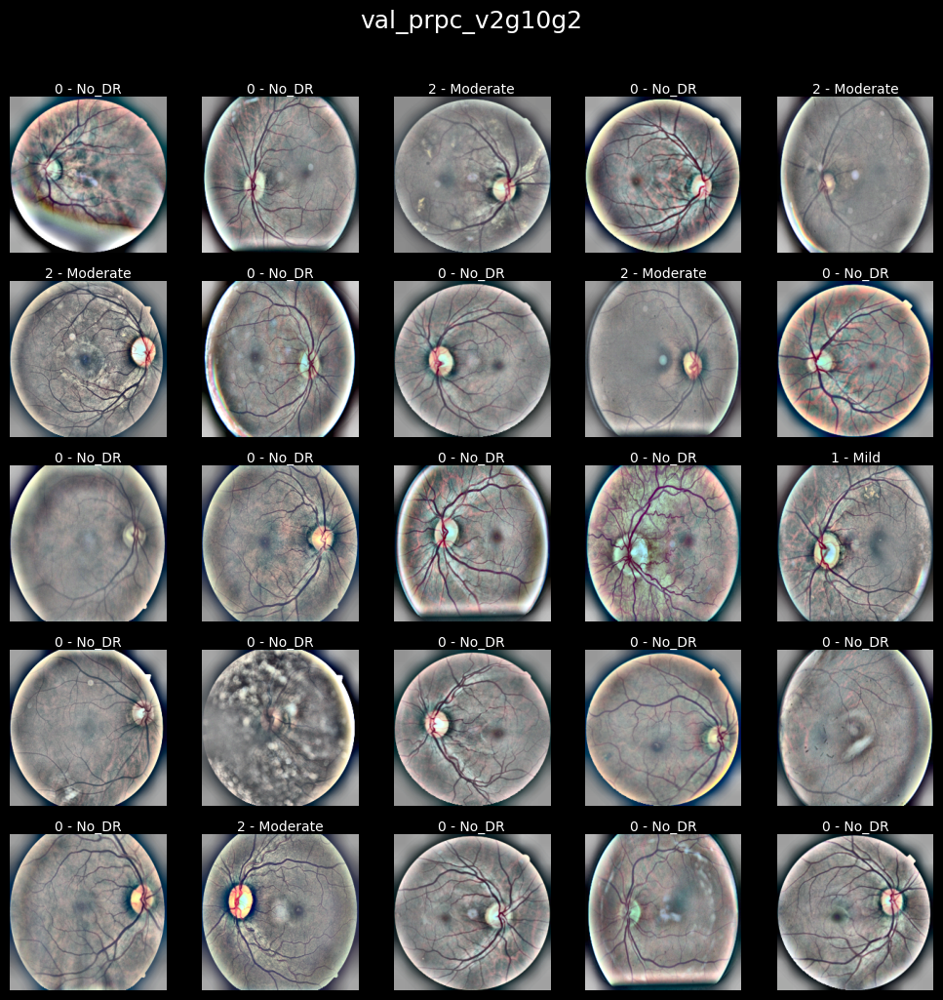

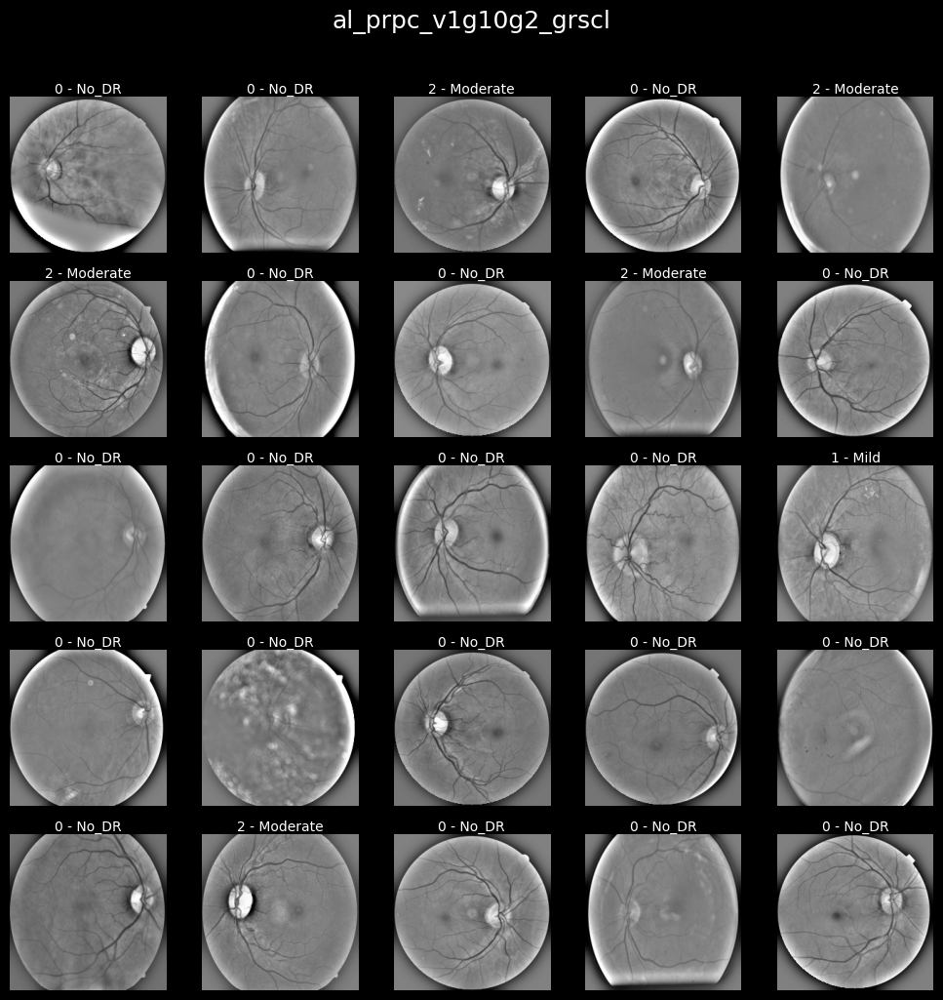

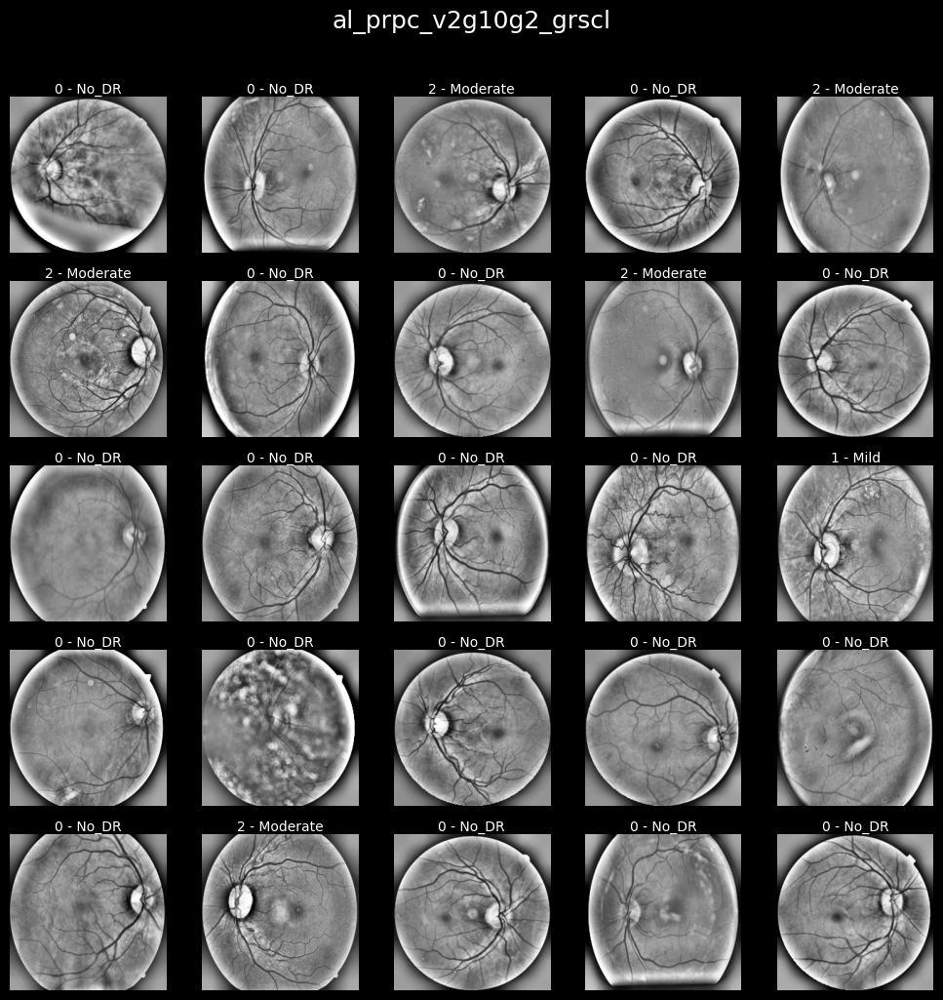

In [108]:
show_df_imgs(val_prpc_v1g10g2[:50],title="val_prpc_v1g10g2")
show_df_imgs(val_prpc_v2g10g2[:50],title="val_prpc_v2g10g2")
show_df_imgs(val_prpc_v1g10g2_grscl[:50],title="val_prpc_v1g10g2_grscl",grayscale=True)
show_df_imgs(val_prpc_v2g10g2_grscl[:50],title="val_prpc_v2g10g2_grscl",grayscale=True)

In [109]:
save_preprocessed(df_ds=val_prpc_v1g10g2,
                  folder_name = "_valprpc_ver1_sigmax10_gain2_17000")

save_preprocessed(df_ds=val_prpc_v2g10g2,
                  folder_name = "val_prpc_ver2_sigmax10_gain2_17000")

save_preprocessed(df_ds=val_prpc_v1g10g2_grscl,
                  folder_name = "val_prpc_ver1_sigmax10_gain2_grscl_17000")

save_preprocessed(df_ds=val_prpc_v2g10g2_grscl,
                  folder_name = "val_prpc_ver2_sigmax10_gain2_grscl_17000")

Saved 17000 images into '_valprpc_ver1_sigmax10_gain2_17000' with 5 class folders.
Saved 17000 images into 'val_prpc_ver2_sigmax10_gain2_17000' with 5 class folders.
Saved 17000 images into 'val_prpc_ver1_sigmax10_gain2_grscl_17000' with 5 class folders.
Saved 17000 images into 'val_prpc_ver2_sigmax10_gain2_grscl_17000' with 5 class folders.


In [ ]:
# Testing our new version for ver2 preprocessing , which applied a binary mask to set the outside part of the retina to black


In [29]:
df_val_complete.columns

Index(['path', 'image', 'level'], dtype='object')

In [31]:
df_val_complete.head()

,path,image,level
0,"[[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...",10003_left,0
1,"[[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...",10003_right,0
2,"[[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...",10007_left,0
3,"[[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...",10007_right,0
4,"[[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...",10009_left,0


In [32]:
df_val_complete.drop("image",axis=1,inplace=True)
df_val_complete.rename(columns={"path":"image","level":"label"},inplace=True)
df_val_complete.head()

,image,label
0,"[[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...",0
1,"[[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...",0
2,"[[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...",0
3,"[[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...",0
4,"[[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...",0


In [33]:
prpc_v2s10g2_blckbg_df = df_val_complete.copy(deep=True)
test_prpc = df_val_complete[:50].copy(deep=True)

In [36]:
type(test_prpc["image"].values)

numpy.ndarray

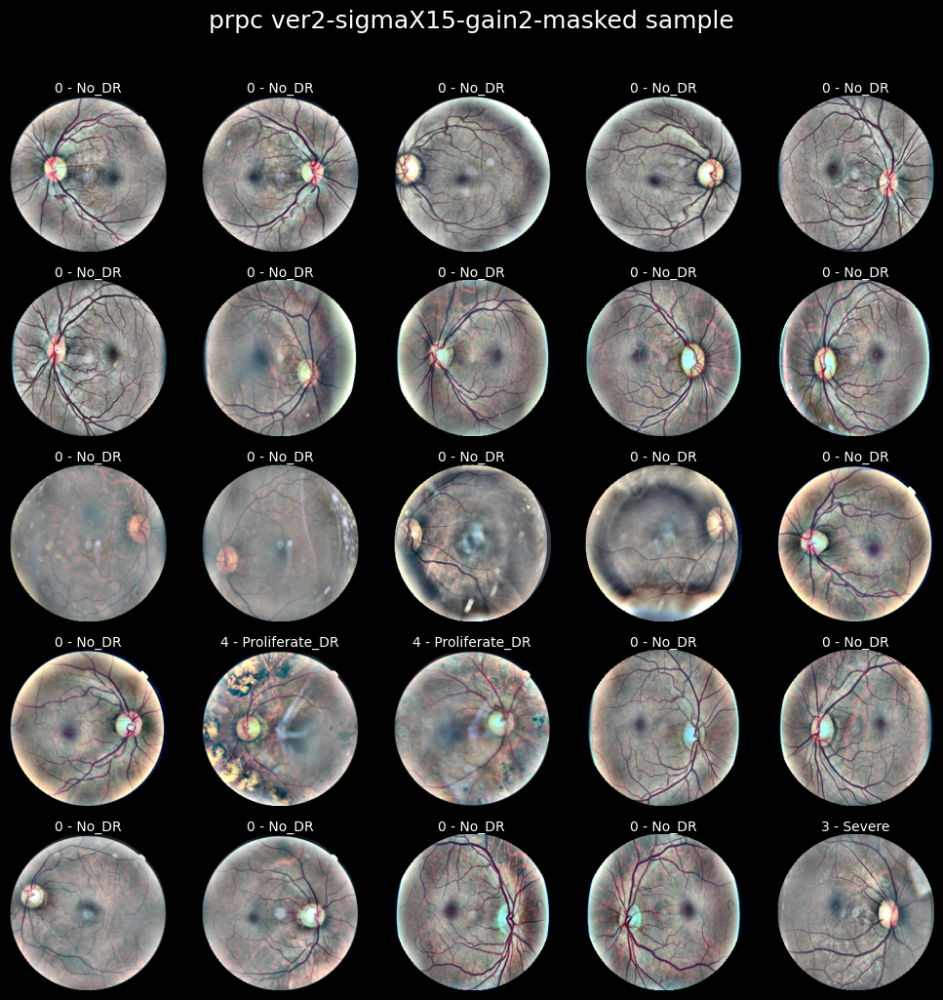

In [40]:
test_prpc = df_val_complete[:50].copy(deep=True)
test_prpc["image"] = test_prpc["image"].apply(lambda i : preprocessing_2_with_mask(img = i, sigmaX=15,gain=2))
show_df_imgs(test_prpc[:50],title="prpc ver2-sigmaX15-gain2-masked sample",fname="prpc_v2s15g2_masked_sample.png",save=True)

In [42]:
prpc_v2s10g2_blckbg_df["image"] = prpc_v2s10g2_blckbg_df["image"].apply(lambda i : preprocessing_2_with_mask(img = i, sigmaX=10,gain=2))

In [43]:
save_preprocessed(df_ds=prpc_v2s10g2_blckbg_df,
                  folder_name = "prpc_ver2_sigmax10_gain2_masked_35108")

Saved 35108 images into 'prpc_ver2_sigmax10_gain2_masked_17000' with 5 class folders.


In [44]:
save_preprocessed(df_ds=test_prpc,
                  folder_name = "prpc_ver2_sigmax10_gain2_masked_50")

Saved 50 images into 'prpc_ver2_sigmax10_gain2_masked_50' with 5 class folders.


In [45]:
len(df_ds)

3540

In [46]:
df_ds.head()

,image,label
0,"[[[0, 0, 0], [1, 1, 1], [0, 0, 0], [0, 0, 0], ...",0
1,"[[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...",4
2,"[[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...",3
3,"[[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...",0
4,"[[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...",4


In [47]:
prpc_v2_3540 = df_ds.copy(deep=True)

In [48]:
prpc_v2_3540["image"] = prpc_v2_3540["image"].apply(lambda i : preprocessing_2_with_mask(img = i, sigmaX=10,gain=2))

In [49]:
save_preprocessed(df_ds=prpc_v2_3540,
                  folder_name = "prpc_ver2_sigmax10_gain2_masked_3540")

Saved 3540 images into 'prpc_ver2_sigmax10_gain2_masked_3540' with 5 class folders.


In [11]:
len(df_val_complete)

35108

In [14]:
df_val_complete["level"].value_counts()

level
0    25802
2     5288
1     2438
3      872
4      708
Name: count, dtype: int64

## Preparing some images for binary classification between non_fundus and fundus

In [15]:
non_fundus_paths = get_paths("/dataset/non_fundus")
non_fundus_paths[:5]

['C:\\Users\\thaim\\Documents\\Machine learning/dataset/non_fundus\\000000000139.jpg',
 'C:\\Users\\thaim\\Documents\\Machine learning/dataset/non_fundus\\000000000285.jpg',
 'C:\\Users\\thaim\\Documents\\Machine learning/dataset/non_fundus\\000000000632.jpg',
 'C:\\Users\\thaim\\Documents\\Machine learning/dataset/non_fundus\\000000000724.jpg',
 'C:\\Users\\thaim\\Documents\\Machine learning/dataset/non_fundus\\000000000776.jpg']

In [16]:
non_fundus_df = pd.DataFrame({
    "path":non_fundus_paths,
    "label":0
})
non_fundus_df.head()

,path,label
0,C:\Users\thaim\Documents\Machine learning/data...,0
1,C:\Users\thaim\Documents\Machine learning/data...,0
2,C:\Users\thaim\Documents\Machine learning/data...,0
3,C:\Users\thaim\Documents\Machine learning/data...,0
4,C:\Users\thaim\Documents\Machine learning/data...,0


In [17]:
non_fundus_df["path"] = non_fundus_df["path"].apply(lambda p : load_img(p))

In [18]:
non_fundus_df.rename(columns={"path":"image"},inplace = True)
non_fundus_df.head()

,image,label
0,"[[[170, 136, 73], [173, 142, 77], [175, 144, 7...",0
1,"[[[81, 137, 62], [62, 117, 36], [51, 107, 16],...",0
2,"[[[100, 101, 87], [90, 91, 75], [92, 94, 73], ...",0
3,"[[[47, 53, 67], [33, 39, 51], [37, 46, 55], [3...",0
4,"[[[144, 93, 64], [140, 93, 65], [137, 96, 68],...",0


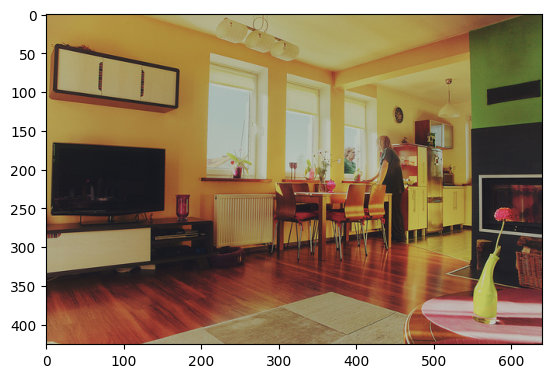

In [20]:
plt.imshow(non_fundus_df["image"].iloc[0])

In [27]:
fundus_1 = df_ds["image"].copy(deep = True)
fundus_2 = df_ds_val["image"].copy(deep=True)
fundus_df = pd.concat([fundus_1,fundus_2],ignore_index=True)
fundus_df.head()

0    [[[0, 0, 0], [1, 1, 1], [0, 0, 0], [0, 0, 0], ...
1    [[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...
2    [[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...
3    [[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...
4    [[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...
Name: image, dtype: object

In [31]:
fundus_df = fundus_df.to_frame()
fundus_df["label"] = 1
fundus_df.columns

Index(['image', 'label'], dtype='object')

In [32]:
fundus_df.head()

,image,label
0,"[[[0, 0, 0], [1, 1, 1], [0, 0, 0], [0, 0, 0], ...",1
1,"[[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...",1
2,"[[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...",1
3,"[[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...",1
4,"[[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...",1


In [34]:
binary_classification_df = pd.concat([fundus_df,non_fundus_df],ignore_index = True)
binary_classification_df["label"].value_counts()

label
1    5310
0    5000
Name: count, dtype: int64

In [48]:
def general_preprocess(image, img_size=224):
    resized = cv2.resize(
        image,
        (img_size, img_size),
        interpolation=cv2.INTER_AREA
    )
    blur = cv2.GaussianBlur(resized, (0, 0), sigmaX=10)
    pre_clahe = cv2.addWeighted(resized, 2, blur, -2, 128)
    lab = cv2.cvtColor(pre_clahe, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l2 = clahe.apply(l)
    lab2 = cv2.merge((l2, a, b))
    post_clahe = cv2.cvtColor(lab2, cv2.COLOR_LAB2RGB)
    return np.clip(post_clahe, 0, 255).astype(np.uint8)

In [57]:
binary_classification_df["image"] = binary_classification_df["image"].apply(lambda i:general_preprocess(i))

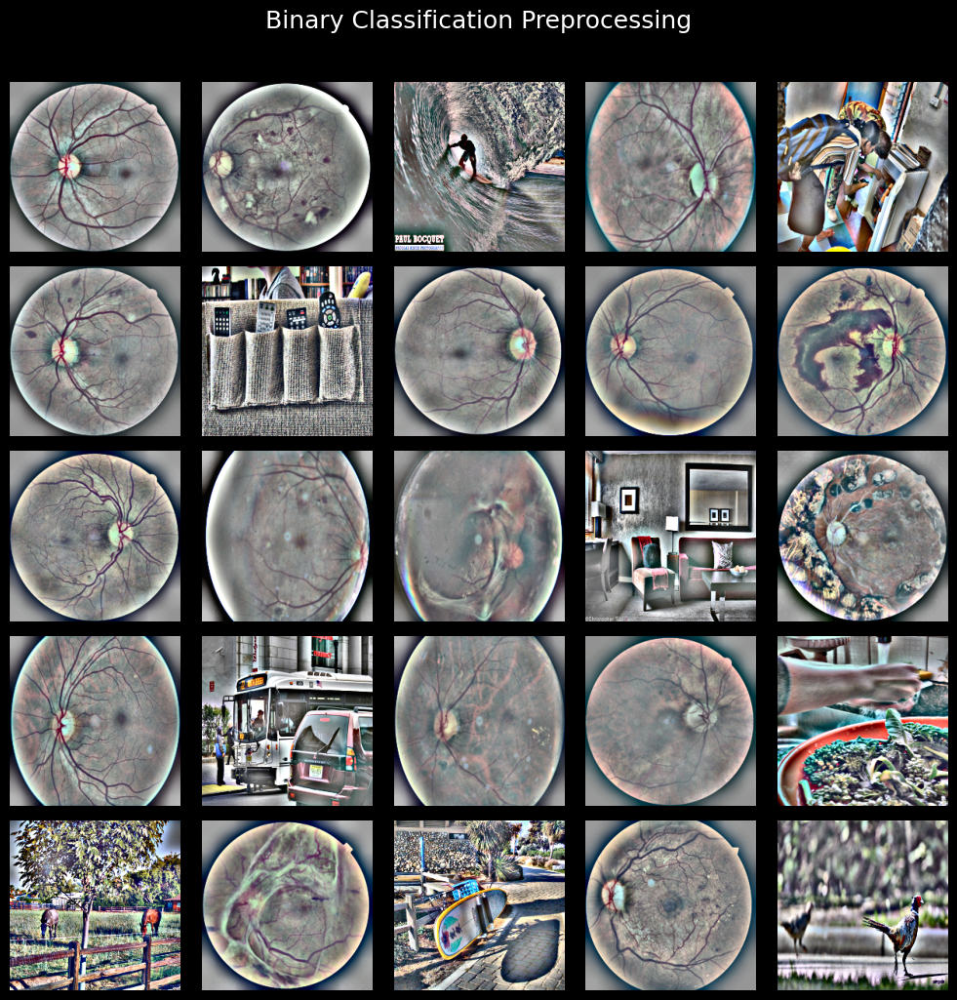

In [64]:
shuffled = binary_classification_df.sample(n=len(binary_classification_df))
show_df_imgs(shuffled[:50],label=False,save=True,fname="BinaryClassificationPrpc.png",title="Binary Classification Preprocessing")

In [65]:
save_preprocessed(folder_name="Binary Classification Dataset",df_ds = shuffled)

Saved 10310 images into 'Binary Classification Dataset' with 2 class folders.
